# CardioRisk Studio — Prédiction de la maladie coronarienne (Heart Disease UCI)

**Objectif** : à partir de 13 variables cliniques, estimer la probabilité qu'un patient présente une maladie coronarienne (rétrécissement > 50 %) et identifier les variables qui pèsent le plus.

**Données** : UCI Heart Disease (Janosi, Steinbrunn, Pfisterer & Detrano, 1989 ; DOI 10.24432/C52P4X, licence CC BY 4.0). **920 lignes brutes → 918 patients** après retrait de 2 doublons exacts.

**Structure** : Partie A — cadrage (A1–A4) · Partie B — réalisation en 17 phases.

**Convention** : une cellule de code = une tâche, précédée de *Tâche / Pourquoi* et suivie d'une interprétation courte.

## Plan — 18 phases

| Phase | Contenu |
|---|---|
| 1 | Chargement du CSV (920 × 16) |
| 2 | Audit structurel : `info`, `describe`, modalités |
| 3 | Nettoyage : manquants, zéros invalides, doublons, modalités (→ 918 × 14) |
| 4 | Cible binaire `target`, familles `NUM` / `CAT` |
| 5 | Analyse visuelle : distributions, boxplots, taux par modalité |
| 6 | Corrélation de Pearson (numériques + cible) et taux de malades par modalité |
| 7 | Split train / test stratifié (734 / 184) |
| 8 | Préparation apprise sur le train : médiane, mode, scaling, one-hot |
| 9 | 2 stratégies de valeurs manquantes comparées |
| 10 | Comparaison de modèles |
| 11 | Évaluation test : rapport, R²/MAE/MSE, confusion, ROC |
| 12 | Seuil de décision (rappel ≥ 90 %) |
| 13 | Contrôle visuel réel vs prédit |
| 14 | Importance des variables (permutation) |
| 15 | Prédiction sur nouvelles données |
| 16 | Export `model.joblib` + `model_meta.json` |
| 17 | Conclusion, réponses Q1–Q5, limites |

**Règle d'ordre** : nettoyage (3) → visuel (5) → corrélation (6). Les valeurs extrêmes sont repérées dans l'audit/EDA mais **non supprimées à l'aveugle** : ce sont des cas cliniques plausibles. Imputation, encodage et scaling viennent **après le split**, appris sur le train : c'est de la préparation, pas du nettoyage (aucune fuite).

## A1. Contexte et objectif

Les maladies cardiovasculaires sont une cause majeure de mortalité. À partir de données cliniques simples (âge, tension, cholestérol, fréquence cardiaque maximale, symptômes, résultats d'examen), on cherche à **estimer la probabilité de maladie** pour **orienter plus vite** les patients vers un examen complémentaire.

Le jeu de données regroupe **4 centres** (Cleveland, Hongrie, Suisse, VA Long Beach), des données de 1988 et 13 variables explicatives. La variable `num` (0–4) mesure la sévérité ; on la ramène à une question binaire : **malade (1)** si `num > 0`, **sain (0)** sinon.

**Ce que le modèle fait** : il produit une **probabilité de risque** à partir de variables disponibles avant un examen approfondi. **Ce qu'il ne fait pas** : il ne remplace ni l'examen clinique ni l'avis d'un professionnel de santé.

## A2. Problématique

**Question** : à partir de 13 variables cliniques, peut-on estimer la probabilité qu'un patient présente une maladie coronarienne (rétrécissement > 50 %) avec une fiabilité suffisante pour **prioriser les examens** ?

- **Q1** — Quels facteurs sont associés à la maladie ?
- **Q2** — Quelles variables contribuent le plus à la prédiction ?
- **Q3** — Quelle est la capacité prédictive du modèle ?
- **Q4** — Quel modèle et quelle stratégie de valeurs manquantes retenir ?
- **Q5** — Quel seuil de décision pour limiter les malades manqués ?

## A3. Processus suivi

Dix étapes génériques, déclinées en 18 phases : données brutes → nettoyage → EDA → split → pipeline → comparaison de modèles → évaluation → seuil → importance → export.


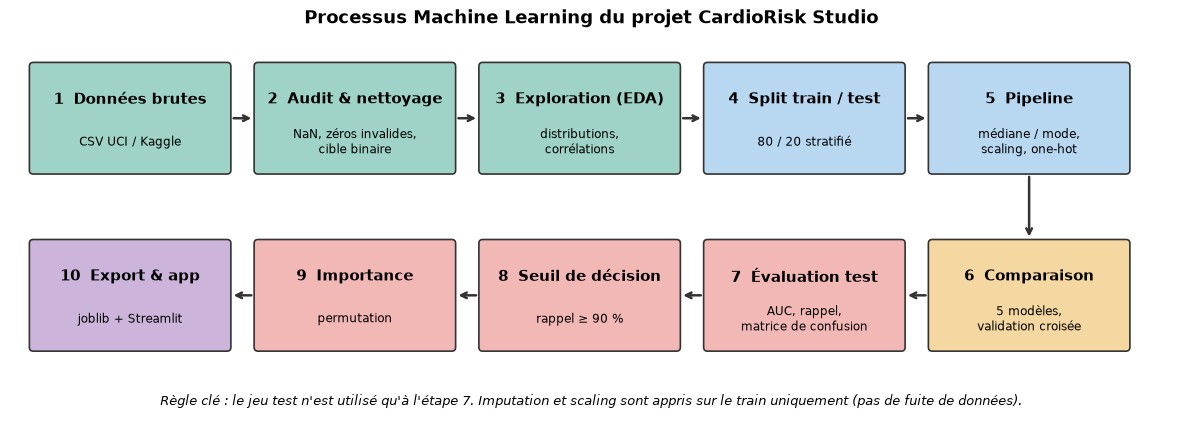

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

steps = [
    ("1  Données brutes", "CSV UCI / Kaggle"),
    ("2  Audit & nettoyage", "NaN, zéros invalides,\ncible binaire"),
    ("3  Exploration (EDA)", "distributions,\ncorrélations"),
    ("4  Split train / test", "80 / 20 stratifié"),
    ("5  Pipeline", "médiane / mode,\nscaling, one-hot"),
    ("6  Comparaison", "5 modèles,\nvalidation croisée"),
    ("7  Évaluation test", "AUC, rappel,\nmatrice de confusion"),
    ("8  Seuil de décision", "rappel ≥ 90 %"),
    ("9  Importance", "permutation"),
    ("10  Export & app", "joblib + Streamlit"),
]
colors = ["#9FD3C7", "#9FD3C7", "#9FD3C7", "#B8D8F2", "#B8D8F2", "#F5D7A1", "#F2B8B5", "#F2B8B5", "#F2B8B5", "#CDB4DB"]

fig, ax = plt.subplots(figsize=(15, 5.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 5.2); ax.axis("off")
w, h = 2.5, 1.35
pos = [(0.3 + i * 2.9, 3.4) for i in range(5)] + [(0.3 + (4 - i) * 2.9, 1.1) for i in range(5)]
for (x, y), (t, s), c in zip(pos, steps, colors):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=c, ec="#333", lw=1.2))
    ax.text(x + w/2, y + h*0.68, t, ha="center", va="center", fontsize=10.5, weight="bold")
    ax.text(x + w/2, y + h*0.27, s, ha="center", va="center", fontsize=8.5)
for i in range(9):
    (x1, y1), (x2, y2) = pos[i], pos[i + 1]
    if i < 4:   a, b = (x1 + w + 0.05, y1 + h/2), (x2 - 0.05, y2 + h/2)
    elif i == 4: a, b = (x1 + w/2, y1 - 0.05), (x2 + w/2, y2 + h + 0.05)
    else:       a, b = (x1 - 0.05, y1 + h/2), (x2 + w + 0.05, y2 + h/2)
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", lw=1.8, color="#333"))
ax.text(7.5, 0.35, "Règle clé : le jeu test n'est utilisé qu'à l'étape 7. Imputation et scaling sont appris sur le train uniquement (pas de fuite de données).",
        ha="center", fontsize=9.5, style="italic")
plt.title("Processus Machine Learning du projet CardioRisk Studio", fontsize=13, weight="bold")
plt.show()

## A4. Attributs techniques

13 variables explicatives + 1 cible (`target`). Noms du CSV Kaggle : la fréquence cardiaque maximale est `thalch` (`thalach` dans UCI).

| Variable | Signification | Famille | Type | Préparation |
|---|---|---|---|---|
| `age` | Âge | Démographique | Numérique | médiane + scaling |
| `sex` | Sexe | Démographique | Catégorielle (2) | mode + one-hot |
| `cp` | Type de douleur thoracique | Symptôme | Catégorielle (4) | mode + one-hot |
| `trestbps` | Tension artérielle au repos (mmHg) | Mesure | Numérique | médiane + scaling |
| `chol` | Cholestérol (mg/dL) | Mesure | Numérique | médiane + scaling |
| `fbs` | Glycémie à jeun > 120 mg/dL | Mesure | Catégorielle (2) | mode + one-hot |
| `restecg` | Résultat ECG au repos | Examen | Catégorielle (3) | mode + one-hot |
| `thalch` | Fréquence cardiaque maximale | Examen | Numérique | médiane + scaling |
| `exang` | Angine induite par l'effort | Symptôme | Catégorielle (2) | mode + one-hot |
| `oldpeak` | Dépression ST à l'effort | Examen | Numérique | médiane + scaling |
| `slope` | Pente du segment ST | Examen | Catégorielle (3) | mode + one-hot |
| `ca` | Nombre de vaisseaux colorés (0–3) | Examen | Numérique (discret) | médiane + scaling + indicateur |
| `thal` | Résultat de scintigraphie | Examen | Catégorielle (3) | mode + one-hot |
| `num` → `target` | Sévérité 0–4 recodée en 0 / 1 | Cible | Binaire | — |

### Glossaire des métriques

| Terme | Sens | Lecture |
|---|---|---|
| **AUC** (ROC-AUC) | Probabilité que le modèle note un malade plus haut qu'un sain, tous seuils confondus | 0,5 = hasard ; 1 = parfait |
| **CV** (validation croisée) | Le train est coupé en 5 plis ; chacun sert une fois de validation | plus stable qu'un seul split |
| **Rappel** | Malades détectés / malades réels | prioritaire ici : manquer un malade coûte plus cher |
| **Précision** | Vrais malades parmi les patients signalés | limite les fausses alertes |
| **Seuil** | Probabilité à partir de laquelle on déclare « à risque » | 0,50 par défaut ; ici calculé (Phase 13) |

## Partie B — Réalisation

## Phase 1 — Chargement

**Tâche** : importer les bibliothèques puis lire `heart_disease_uci.csv` dans `df`.
**Pourquoi** : on travaille sur une copie en mémoire, le fichier source reste intact.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

**Comment lire ce fichier depuis le lien GitHub ?**

Le lien `https://github.com/.../blob/main/heart_disease_uci.csv` est une **page HTML** : `pd.read_csv` y verrait du HTML, pas du CSV. Il faut la version **raw** (`raw.githubusercontent.com/...`) qui renvoie le fichier brut. Le code ci-dessous tente le lien raw et **retombe sur la copie locale** si le réseau est absent, ce qui rend le notebook reproductible dans les deux cas.

In [3]:
# Lecture des données : le lien GitHub "blob" affiche la page web, il faut la version "raw"
URL_CSV = "https://raw.githubusercontent.com/bennoomenfaker/cardiorisk-studio/main/heart_disease_uci.csv"

try:
    df = pd.read_csv(URL_CSV)                    # lecture directe depuis GitHub
    origine = "GitHub (raw)"
except Exception:                                # hors ligne ou fichier renommé
    df = pd.read_csv("heart_disease_uci.csv")    # copie locale du dépôt
    origine = "fichier local"

print("Source :", origine, "| dimensions :", df.shape)

Source : GitHub (raw) | dimensions : (920, 16)


**Interprétation** : `(920, 16)` = **920 lignes brutes** × 16 colonnes (`id`, `dataset`, 13 variables, `num`).

⚠️ **920 ou 918 ?** 920 = lignes du fichier CSV ; **918 = patients** après retrait des **2 doublons exacts** en Phase 3. Tout le reste du notebook travaille sur 918.


In [4]:
df.head() 


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


**Interprétation** : une ligne = un patient ; colonnes numériques et texte mélangées → un audit des types est nécessaire.

## Phase 2 — Audit structurel

**Tâche** : décrire les données sans rien modifier (`info`, `describe`, effectifs des modalités).
**Pourquoi** : connaître types, échelles et valeurs manquantes avant toute décision.


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


**Interprétation** : colonnes complètes (`age`, `sex`, `cp`, `num`…) ; colonnes très incomplètes : `ca` (309 valeurs), `thal` (434), `slope` (611).


In [6]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


**Interprétation** : `chol` minimum 0 et `trestbps` minimum 0 sont **impossibles** → manquants déguisés (corrigés en 3.1). `oldpeak` négatif est plausible. `age` : 28–77 ans, moyenne 53,5.


In [7]:
df.describe(include=["object", "str"])


,sex,dataset,cp,fbs,restecg,exang,slope,thal
count,920,920,920,830,918,865,611,434
unique,2,4,4,2,3,2,3,3
top,Male,Cleveland,asymptomatic,False,normal,False,flat,normal
freq,726,304,496,692,551,528,345,196


In [8]:
for col in ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]:
    print(col, "->", df[col].value_counts(dropna=False).to_dict())




sex -> {'Male': 726, 'Female': 194}
cp -> {'asymptomatic': 496, 'non-anginal': 204, 'atypical angina': 174, 'typical angina': 46}
fbs -> {False: 692, True: 138, nan: 90}
restecg -> {'normal': 551, 'lv hypertrophy': 188, 'st-t abnormality': 179, nan: 2}
exang -> {False: 528, True: 337, nan: 55}
slope -> {'flat': 345, nan: 309, 'upsloping': 203, 'downsloping': 63}
thal -> {nan: 486, 'normal': 196, 'reversable defect': 192, 'fixed defect': 46}


In [9]:
print("Nombre de valeurs distinctes par colonne :")
display(df.nunique().sort_values(ascending=False).to_frame("valeurs_uniques"))

Nombre de valeurs distinctes par colonne :


,valeurs_uniques
id,920
chol,217
thalch,119
trestbps,61
oldpeak,53
age,50
num,5
cp,4
dataset,4
ca,4


**Interprétation** : `sex` 79 % masculin ; 4 centres (Cleveland le plus gros, 304) ; `cp = asymptomatic` majoritaire (496) ; `thal` et `slope` très incomplets.

## Phase 3 — Nettoyage de base (avant visuel et corrélation)

| Étape | Action |
|---|---|
| 3.0 | Auditer les valeurs manquantes (nombre + %) |
| 3.1 | Remplacer les valeurs impossibles (`chol = 0`, `trestbps = 0`) par `NaN` |
| 3.2 | Vérifier la répartition des manquants entre les 4 centres |
| 3.3 | Supprimer les colonnes inutiles (`id`, `dataset`) et les doublons exacts |
| 3.4 | Harmoniser les modalités catégorielles (espaces, libellés) |

L'imputation n'est **pas** faite ici : elle est apprise après le split (Phase 9).


In [10]:
tableau = pd.DataFrame({
    "manquants": df.isna().sum(),
    "% manquants": (df.isna().mean() * 100).round(1)
})
tableau[tableau["manquants"] > 0].sort_values("% manquants", ascending=False)

,manquants,% manquants
ca,611,66.4
thal,486,52.8
slope,309,33.6
fbs,90,9.8
oldpeak,62,6.7
trestbps,59,6.4
exang,55,6.0
thalch,55,6.0
chol,30,3.3
restecg,2,0.2


### 3.0 — Valeurs manquantes

| Variable | Manquants | % |
|---|---:|---:|
| `ca` | 611 | 66,4 % |
| `thal` | 486 | 52,8 % |
| `slope` | 309 | 33,6 % |
| `fbs` | 90 | 9,8 % |
| `oldpeak` | 62 | 6,7 % |
| `trestbps` | 59 | 6,4 % |
| `exang` | 55 | 6,0 % |
| `thalch` | 55 | 6,0 % |
| `chol` | 30 | 3,3 % |
| `restecg` | 2 | 0,2 % |

**Décision** : aucune ligne n'est supprimée (on perdrait presque tout) et `ca`/`thal` sont des examens utiles → **imputation** dans le pipeline (Phase 9) avec indicateur de manquant ; 3 stratégies comparées en Phase 10.

### 3.1 — Zéros invalides

**Tâche** : remplacer `chol = 0` et `trestbps = 0` par `NaN` (manquants déguisés).
**Pourquoi** : ces valeurs n'existent pas chez un patient vivant.


In [11]:
print("chol = 0       :", (df["chol"] == 0).sum())
print("trestbps = 0   :", (df["trestbps"] == 0).sum())

df["chol"] = df["chol"].replace(0, np.nan)
df["trestbps"] = df["trestbps"].replace(0, np.nan)

print("Manquants chol après correction     :", df["chol"].isna().sum())
print("Manquants trestbps après correction :", df["trestbps"].isna().sum())

chol = 0       : 172
trestbps = 0   : 1
Manquants chol après correction     : 202
Manquants trestbps après correction : 60


### 3.2 — Manquants par centre

**Tâche** : vérifier si les manquants sont répartis au hasard entre les 4 centres.
**Pourquoi** : si une variable n'est mesurée que dans un hôpital, son association avec la maladie ne vaut que pour cet hôpital.


In [12]:
# Valeurs réellement observées par centre (le dataset n'est pas encore retiré)
df.groupby("dataset")[["ca", "thal", "slope"]].count().assign(patients=df["dataset"].value_counts())

,ca,thal,slope,patients
dataset,,,,
Cleveland,299,301,303,304
Hungary,3,28,104,293
Switzerland,5,71,106,123
VA Long Beach,2,34,98,200


**Interprétation** : les manquants ne sont **pas aléatoires**. `ca` n'est connu que pour **309 patients, dont 299 de Cleveland** (Hongrie 3, Suisse 5, VA Long Beach 2) ; `thal` pour 434 patients (301 Cleveland, 71 Suisse, 34 VA Long Beach, 28 Hongrie).

Conséquence : l'association de `ca` avec la maladie est mesurée **presque uniquement sur Cleveland**. C'est une limite à citer, et la raison d'être des **indicateurs de manquant** du pipeline (le modèle sait qu'une valeur a été inventée).

### 3.3 — Colonnes inutiles et doublons

**Tâche** : retirer `id` et `dataset`, puis supprimer les doublons exacts.
**Pourquoi** : `id` n'a aucun sens médical, `dataset` (le centre) ferait fuiter un contexte géographique ; un profil identique compté deux fois pèserait double dans la CV et le test.


In [13]:
df = df.drop(columns=["id", "dataset"])

# Doublons exacts : un même profil clinique compté deux fois fausserait la validation
# croisée et le test (la même observation serait utilisée deux fois).
n_dup = int(df.duplicated().sum())
print("Doublons exacts :", n_dup)
display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head(n_dup))

df = df.drop_duplicates().reset_index(drop=True)
print("Dimensions après retrait des doublons :", df.shape)


Doublons exacts : 2


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
404,49,Female,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,NaN,NaN,NaN,0
405,49,Female,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,NaN,NaN,NaN,0


Dimensions après retrait des doublons : (918, 14)


**Interprétation** : **2 doublons exacts** retirés (ids 405/406 en Hongrie, 860/908 à VA Long Beach : mêmes 13 variables, même diagnostic, même centre) → **918 patients** × 14 colonnes. Ces lignes sont indiscernables, on ne peut pas les départager : les compter deux fois biaiserait le test.


### 3.4 — Harmonisation des modalités

**Tâche** : retirer les espaces superflus et vérifier que chaque variable catégorielle ne contient que les modalités attendues.
**Pourquoi** : `"Male "` et `"Male"` créeraient deux catégories pour la même information et le One-Hot les traiterait séparément. On ne change **pas** la casse de `fbs` et `exang` (`"True"` / `"False"`) : ces libellés sont utilisés dans les scénarios et le formulaire de l'application.


In [14]:
# Harmonisation : espaces multiples retirés, puis contrôle des libellés attendus.
ATTENDU = {
    "sex": {"Male", "Female"},
    "cp": {"typical angina", "atypical angina", "non-anginal", "asymptomatic"},
    "fbs": {"True", "False"},
    "restecg": {"normal", "lv hypertrophy", "st-t abnormality"},
    "exang": {"True", "False"},
    "slope": {"upsloping", "flat", "downsloping"},
    "thal": {"normal", "fixed defect", "reversable defect"},
}

for col, modalites in ATTENDU.items():
    propre = df[col].dropna().astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    df[col] = propre.reindex(df.index)
    inconnues = set(df[col].dropna().unique()) - modalites
    if inconnues:
        print(f"⚠️ {col} : modalités inattendues {sorted(inconnues)}")

print("Modalités après harmonisation :")
for col, modalites in ATTENDU.items():
    print(f"  {col:8s} -> {sorted(df[col].dropna().unique())}")


Modalités après harmonisation :
  sex      -> ['Female', 'Male']
  cp       -> ['asymptomatic', 'atypical angina', 'non-anginal', 'typical angina']
  fbs      -> ['False', 'True']
  restecg  -> ['lv hypertrophy', 'normal', 'st-t abnormality']
  exang    -> ['False', 'True']
  slope    -> ['downsloping', 'flat', 'upsloping']
  thal     -> ['fixed defect', 'normal', 'reversable defect']


## Phase 4 — Cible binaire et familles de variables

**Tâche** : créer `target = 1 si num > 0`, puis séparer `NUM` (6 numériques) et `CAT` (7 catégorielles).
**Pourquoi** : `num` va de 0 à 4 ; notre question est binaire. Les deux familles ne reçoivent pas le même prétraitement.


In [15]:
df['target'] = (df['num'] > 0).astype(int)    # 0 = sain, 1 = maladie
df = df.drop(columns='num')

counts = df['target'].value_counts().sort_index()
pct = (df['target'].value_counts(normalize=True).sort_index() * 100).round(1)
resume = pd.DataFrame({'effectif': counts, 'pourcentage_%': pct})
resume.index = ['Sain (0)', 'Malade (1)']
resume


,effectif,pourcentage_%
Sain (0),410,44.7
Malade (1),508,55.3


**🔎 Interprétation**
- **508 malades (55,3 %)** et **410 sains (44,7 %)** : les classes sont **assez équilibrées**. Pas besoin de rééquilibrage, et l'accuracy reste utilisable.
- Un modèle qui répondrait toujours « malade » aurait déjà **55 %** d'accuracy : c'est le **score minimal à battre**.


In [16]:
NUM = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]
CAT = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]



## Phase 5 — Analyse visuelle

**Tâche** : décrire la distribution de la cible, les moyennes par classe, les distributions numériques et les taux de malades par modalité.
**Pourquoi** : avant toute modélisation, voir la forme des variables, repérer les séparations nettes et les chevauchements.


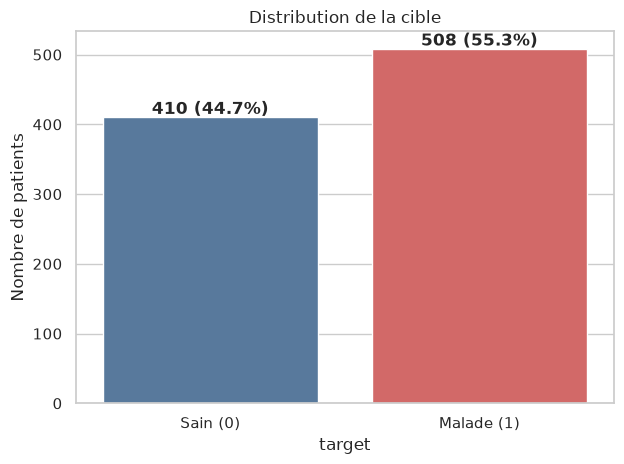

In [17]:
ax = sns.countplot(data=df, x='target', hue='target', palette=['#4C78A8', '#E45756'], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Sain (0)', 'Malade (1)'])
ax.set_title('Distribution de la cible')
ax.set_ylabel('Nombre de patients')
for i, (n, p) in enumerate(zip(counts, pct)):
    ax.text(i, n + 5, f'{int(n)} ({p:.1f}%)', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


**Nom / lecture** : diagramme en barres de la cible. La hauteur donne l'effectif ; les classes sont déséquilibrées à peine (55 % / 45 %), donc aucune correction n'est nécessaire.


In [18]:
df.groupby("target")[NUM].mean().round(1)

,age,trestbps,chol,thalch,oldpeak,ca
target,,,,,,
0,50.6,130.0,240.2,148.8,0.4,0.3
1,55.9,134.2,254.1,128.3,1.3,1.1


**🔎 Interprétation**
- Les malades sont **plus âgés** (55,9 ans contre 50,6), ont une **fréquence cardiaque maximale plus basse** (`thalch` 128 contre 149), un **`oldpeak` plus élevé** (1,3 contre 0,4) et **plus de vaisseaux atteints** (`ca` 1,1 contre 0,3).
- `trestbps` (134 contre 130) et `chol` (254 contre 240) diffèrent **peu**.
- Les moyennes sont sensibles aux valeurs extrêmes : on vérifie avec des boxplots.


**Lecture rapide** : on compare la distribution des variables numériques par cible (voir moyennes ci-dessus et heatmaps ci-dessous). Les boxplots détaillés ne sont pas conservés pour alléger le notebook.


In [19]:
# Graphiques détaillés boxplot supprimés (redondants avec les moyennes par classe et la corrélation).


In [20]:
# Boxplots numériques redondants supprimés pour simplifier.


**Interprétation** : `thalch` plus bas chez les malades, `oldpeak` et `ca` plus élevés et mieux séparés ; `chol` et `trestbps` se chevauchent beaucoup.


**Tâche** : taux de maladie par modalité des variables catégorielles.
**Pourquoi** : repérer les catégories associées au risque (Q1).


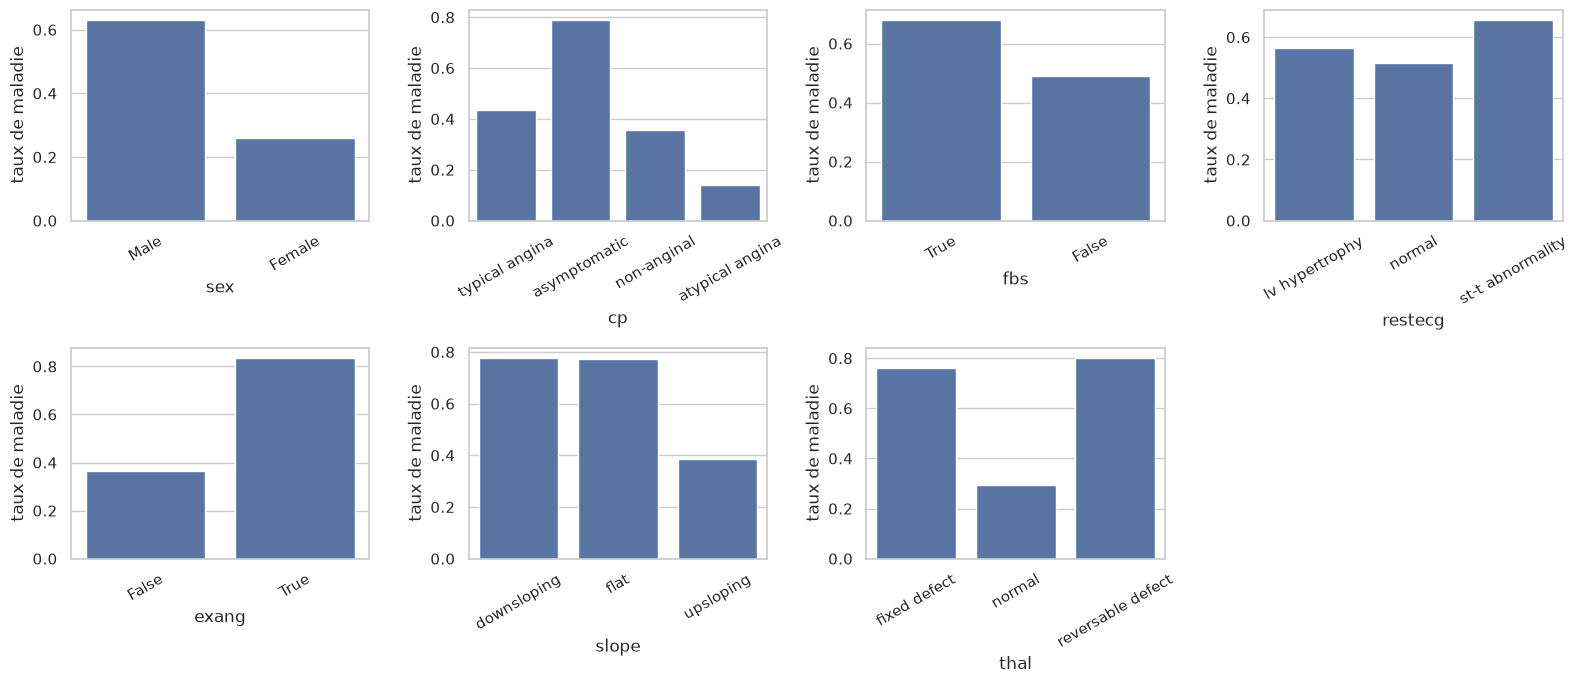

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), CAT):
    sns.barplot(data=df, x=col, y="target", ax=ax, errorbar=None)
    ax.set_ylabel("taux de maladie")
    ax.tick_params(axis="x", rotation=30)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**🔎 Interprétation**
- **`cp`** : `asymptomatic` → **79 %** de malades, contre **14 %** pour `atypical angina`. Résultat contre-intuitif mais connu : l'absence de symptôme caractéristique accompagne souvent une maladie « silencieuse » dans ce jeu.
- **`exang`** (angine à l'effort) : **84 %** si oui, **36 %** si non.
- **`thal`** : 30 % si `normal`, contre ~80 % pour `reversable defect` et ~76 % pour `fixed defect`.
- **`slope`** : `upsloping` 38 %, contre ~77 % pour `flat` et `downsloping`.
- **`sex`** : 63 % des hommes contre 26 % des femmes.
- **`fbs`** 68 % contre 49 %, **`restecg`** 51 à 66 % : associations plus faibles.
- ⚠️ Prudence : l'échantillon est à 79 % masculin et mélange 4 centres, certains écarts peuvent venir de cette composition.


## Phase 6 — Corrélation de Pearson et taux de malades

**Tâche** : mesurer le lien entre les **variables numériques** et la cible, puis décrire les **variables catégorielles** par leur taux de malades.
**Pourquoi deux traitements** : un coefficient de corrélation suppose que les valeurs sont **ordonnées et espacées de façon comparable** (5 ans d'écart = 5 ans). Une catégorie (`cp = asymptomatic`) n'a ni ordre ni distance : on ne peut pas lui attribuer un coefficient. On la décrit donc autrement, par le **pourcentage de malades dans chaque modalité**.
**Point de méthode** : tout ceci se fait **avant le `train_test_split`** et **sans encodage** ; le `OneHotEncoder` n'intervient qu'après le split, dans le pipeline (Phase 9).


**Réponses directes (méthode) :**
- **Quels features sont fortement corrélés à `target` ?** Numériques : `ca` (0,456), `thalch` (-0,393), `oldpeak` (0,386), `age` (0,282) ; `chol` et `trestbps` sont faibles. Catégorielles : on ne calcule pas Pearson, on observe les taux (`cp` asymptomatic 79 %, `exang` 83,6 %, etc.).
- **Élimine-t-on des colonnes ?** On **ne supprime aucune des 13 variables cliniques** sur la seule base de la corrélation. `id`/`dataset` ont été retirés au nettoyage (pas prédictifs/fuite). La corrélation faible n'implique pas inutilité : `chol` a une corrélation faible (0,12) mais une importance permutation notable.
- **Redondance entre features ?** On vérifie la heatmap sans target : aucune paire ne dépasse |r|=0,40, donc pas de multicolinéarité forte à éliminer.
- **Comment les features du modèle sont choisis ?** Les 13 variables cliniques disponibles avant examen approfondi (`NUM+CAT`) sont gardées, puis encodées/scalées dans le pipeline. Le choix final est confirmé par la comparaison de modèles et l'importance par permutation.
- **Missing values : avant ou après corrélation ?** L'**audit** et la correction des zéros impossibles sont faits **avant** EDA/corrélation (Phase 3). L'**imputation** pour le modèle est faite **après le split** dans le `Pipeline` (fit sur train uniquement) pour éviter la fuite de données.


### 7.1 — Corrélation de Pearson (variables numériques)

**Tâche** : calculer la corrélation de Pearson entre variables numériques.
**Deux vues utiles** :
- **avec `target`** : voir quelles variables numériques sont liées à la maladie (signal utile) ;
- **sans `target`** : vérifier la redondance entre variables explicatives (multicolinéarité).

**Comment lire** : `r` proche de +1 = même sens, proche de −1 = sens inverse, proche de 0 = pas de lien linéaire. Entre variables explicatives, |r| > 0,7 signalerait une redondance forte.

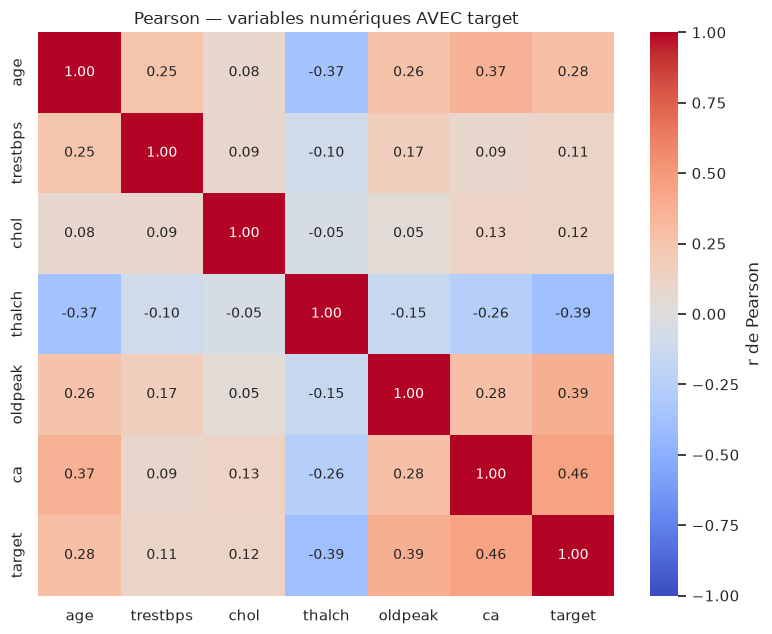

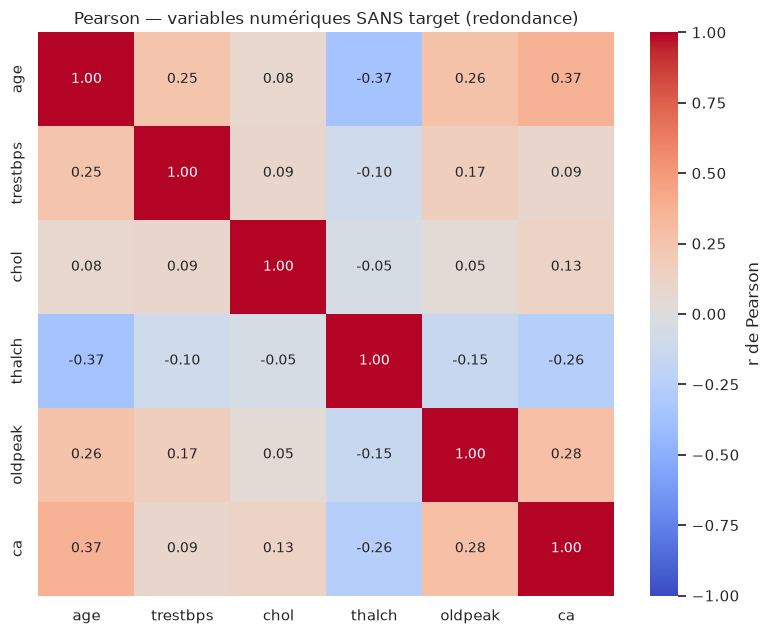

In [22]:
# Corrélation de Pearson : uniquement des variables NUMÉRIQUES (la cible 0/1 en fait partie)
cols_num = NUM + ["target"]
corr_num = df[cols_num].corr(method="pearson")

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_num, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 10}, cbar_kws={"label": "r de Pearson"})
plt.title("Pearson — variables numériques AVEC target")
plt.tight_layout()
plt.show()


corr_num_sabs_cible = df[NUM].corr(method="pearson")

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_num_sabs_cible, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 10}, cbar_kws={"label": "r de Pearson"})
plt.title("Pearson — variables numériques SANS target (redondance)")
plt.tight_layout()
plt.show()



**Interprétation 7.1 — Pearson**

**Entre variables numériques** (aucune redondance) :

| Paire | r | Lecture |
|---|---:|---|
| `age` – `ca` | **0,370** | plus on vieillit, plus on a de vaisseaux touchés |
| `age` – `thalch` | **−0,365** | la fréquence cardiaque maximale baisse avec l'âge (physiologique) |
| `oldpeak` – `ca` | 0,282 | sous-décalage ST marqué ↔ plus de vaisseaux atteints |
| `thalch` – `ca` | −0,264 | moins de réserve cardiaque quand les vaisseaux sont touchés |
| `age` – `oldpeak` | 0,259 | — |
| `age` – `trestbps` | 0,252 | tension de repos un peu plus haute avec l'âge |

**Avec la cible** :

| Variable | r avec `target` | Lecture |
|---|---:|---|
| `ca` | **+0,456** | plus de vaisseaux atteints → plus de malades |
| `thalch` | **−0,393** | fréquence maximale basse → plus de malades |
| `oldpeak` | **+0,386** | sous-décalage ST → risque plus élevé |
| `age` | **+0,282** | — |
| `chol` | +0,119 | lien linéaire faible |
| `trestbps` | +0,115 | lien linéaire faible |

- **Aucune paire explicative ne dépasse |r| = 0,40** : pas de redondance, on garde les 6 variables.
- `age` est au centre de 4 paires : c'est un **facteur de confusion classique** (il pousse à la fois `ca`, `thalch` et `trestbps`).
- Pearson ne mesure qu'une relation **linéaire** ; une relation en U passerait inaperçue, d'où le complément par les taux de malades (7.2).
- ⚠️ `ca` n'est renseigné que pour **309 patients** (surtout Cleveland) : son coefficient vaut pour cette sous-population.

### 7.2 — Variables catégorielles : taux de malades par modalité

**Tâche** : pour chaque variable catégorielle, calculer le **pourcentage de malades** dans chaque modalité, avec l'effectif.
**Pourquoi pas un coefficient** : `sex`, `cp`, `thal`, `slope`… ne sont pas des quantités ; on ne peut pas leur appliquer Pearson. On lit directement ce qui est décidable : « dans cette catégorie, quelle proportion est malade ? ».
**Comment lire** : comparer les modalités **entre elles**, en gardant l'effectif sous les yeux (une modalité à 5 patients ne pèse pas comme une à 500).

In [23]:
# Taux de malades par modalité (variables catégorielles) — aucun coefficient, que des proportions
taux = []
for c in CAT:
    t = df.groupby(c)["target"].agg(["mean", "size"])
    for modalite, ligne in t.iterrows():
        taux.append({
            "variable": c,
            "modalité": modalite,
            "patients": int(ligne["size"]),
            "taux de malades %": round(100 * ligne["mean"], 1),
        })
taux_modalites = pd.DataFrame(taux).sort_values(["variable", "taux de malades %"], ascending=[True, False])
display(taux_modalites)

,variable,modalité,patients,taux de malades %
2,cp,asymptomatic,496,79.0
5,cp,typical angina,46,43.5
4,cp,non-anginal,203,35.5
3,cp,atypical angina,173,13.9
12,exang,True,336,83.6
11,exang,False,527,36.4
7,fbs,True,138,68.1
6,fbs,False,690,49.0
10,restecg,st-t abnormality,178,65.7
8,restecg,lv hypertrophy,188,56.4


**Interprétation 7.2 — ce que disent les taux**

| Variable | Modalité | Patients | Taux de malades |
|---|---|---:|---:|
| `cp` | **asymptomatic** | 496 | **79,0 %** |
| `cp` | typical angina | 46 | 43,5 % |
| `cp` | non-anginal | 203 | 35,5 % |
| `cp` | atypical angina | 173 | 13,9 % |
| `exang` | **True** | 336 | **83,6 %** |
| `exang` | False | 527 | 36,4 % |
| `thal` | **reversable defect** | 192 | **80,2 %** |
| `thal` | fixed defect | 46 | 76,1 % |
| `thal` | normal | 196 | 29,6 % |
| `slope` | downsloping | 63 | 77,8 % |
| `slope` | flat | 345 | 77,1 % |
| `slope` | upsloping | 203 | 38,4 % |
| `sex` | Male | 725 | 63,2 % |
| `sex` | Female | 193 | 25,9 % |
| `fbs` | True | 138 | 68,1 % |
| `fbs` | False | 690 | 49,0 % |
| `restecg` | st-t abnormality | 178 | 65,7 % |
| `restecg` | lv hypertrophy | 188 | 56,4 % |
| `restecg` | normal | 550 | 51,5 % |

- **Les écarts les plus forts sont catégoriels** : `cp = asymptomatic` **79 %** contre `atypical angina` 13,9 % ; `exang = True` 83,6 % contre 36,4 % ; `thal` anormal ~76–80 % contre `normal` 29,6 %.
- `restecg` et `fbs` séparent beaucoup moins (51–66 % et 49–68 %).
- ⚠️ Ces taux sont **descriptifs** : ils mélangent les 4 centres et ne tiennent pas compte des autres variables. Un taux élevé ne prouve pas un effet propre — c'est le modèle (Phase 14) qui départage les contributions.
- **Aucun coefficient n'a été calculé sur une variable catégorielle** : le lien est décrit par des proportions, pas par un `r`.

**Pourquoi ne pas calculer un coefficient sur les catégories ?**

Un coefficient de corrélation compare des **écarts** entre valeurs numériques. `cp` codée 0-1-2-3 n'a pas d'écart qui ait un sens : la différence entre « atypical » et « non-anginal » n'est pas la même qu'entre « non-anginal » et « asymptomatic ». Attribuer un nombre à ces modalités, c'est inventer une distance, et le résultat change de signe selon l'ordre choisi. On préfère donc une lecture par **proportions de malades**, qui ne dépend d'aucun codage.

**Et le One-Hot Encoding ? Il arrive après le split, dans le pipeline.**

| Raison | Explication |
|---|---|
| **Fuite de données** | L'encodeur apprend la liste des modalités sur les données qu'on lui donne. Avant le split, il apprendrait des modalités présentes seulement dans le test. Il reste donc dans le `Pipeline` (Phase 9). |
| **Éviter de fausses relations** | Encoder puis corréler crée des colonnes 0/1 qui se compensent (somme = 1) : les coefficients deviennent illisibles et négatifs par construction entre modalités d'une même variable. |
| **Lisibilité** | 13 variables deviendraient ~26 colonnes : le tableau des taux de malades est plus simple à défendre. |

**La phrase à retenir** : *avant le split, on observe les variables brutes — Pearson pour les numériques, taux de malades pour les catégories — ; après le split, on encode les catégorielles en One-Hot, appris sur `X_train` seulement.*

**Ce que je montre au prof (et ce que je dis)**

| Ce que j'affiche | Ce que je dis | Pourquoi c'est défendable |
|---|---|---|
| **Heatmaps 7.1** (avec target puis sans target) | « La plus forte corrélation avec la maladie est `ca` (0,46), puis `thalch` (−0,39) et `oldpeak` (0,39) ; aucune paire de variables ne dépasse 0,40, donc pas de redondance. » | Pearson exige des variables numériques ; on inclut `target` (0/1) pour le lien à la maladie, et on le retire pour vérifier la redondance entre variables. |
| **Tableau 7.2** (taux par modalité) | « Les catégories ne peuvent pas recevoir de coefficient : je lis le **pourcentage de malades**. `cp = asymptomatic` → 79 % contre 13,9 % pour atypical ; `exang = True` → 83,6 %. » | Une proportion ne dépend d'**aucun codage** et se vérifie à la main. |
| **Phase 15** (permutation) | « Pour l'importance réelle dans le modèle, `cp` arrive largement en tête (+0,064 d'AUC), puis `chol` (0,035) et `oldpeak` (0,027). » | Mesure l'effet **dans le modèle entraîné**, pas une simple corrélation. |

**La phrase à placer** : « Je ne mets pas tout dans une matrice de Pearson : Pearson ne s'applique qu'aux variables numériques. Les catégories sont décrites par leurs taux de malades, et n'entrent dans le modèle qu'après encodage, après le split. »

## Phase 7 — Séparation train / test

**Tâche** : couper les données en 80 % train / 20 % test, en conservant la proportion de malades (`stratify`).
**Pourquoi** : le test ne doit servir qu'une fois, à la fin ; la stratification garantit la même proportion de malades des deux côtés.


In [24]:
from sklearn.model_selection import train_test_split

X = df[NUM + CAT]     # informations du patient
y = df["target"]      # ce qu'on veut prédire

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("% malades -> train :", round(y_train.mean() * 100, 1), "| test :", round(y_test.mean() * 100, 1))

Train : (734, 13) | Test : (184, 13)
% malades -> train : 55.3 | test : 55.4


**🔎 Interprétation**
- **734 patients** pour l'entraînement, **184** pour le test.
- La proportion de malades est quasi identique (**55,3 %** et **55,4 %**) : le découpage est représentatif.
- Le jeu test sera **utilisé une seule fois**, à la fin, pour l'évaluation finale.


## Phase 8 — Préparation apprise sur le train

**Tâche** : médiane (numériques), mode (catégorielles), `StandardScaler`, `OneHotEncoder`, assemblés dans un `Pipeline`.
**Pourquoi** : même traitement appliqué au train, au test et à l'application ; chaque pli de la validation croisée réapprend ses propres statistiques (pas de fuite).


In [25]:
X_train[NUM].agg(["mean", "median"]).round(1)

,age,trestbps,chol,thalch,oldpeak,ca
mean,53.6,132.3,247.6,137.7,0.9,0.7
median,54.0,130.0,240.0,140.0,0.5,0.0


**🔎 Interprétation**
- `chol` : moyenne **247,6** contre médiane **240** : la moyenne est tirée vers le haut par les cholestérols élevés.
- `oldpeak` : 0,9 contre 0,5, et `ca` : **0,7** contre 0 : ces distributions sont **asymétriques** (beaucoup de petites valeurs, quelques grandes).
- La **médiane** (valeur du milieu) n'est **pas influencée par les extrêmes** : c'est le choix le plus sûr pour remplacer un manquant.


In [26]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Statistiques apprises sur le TRAIN uniquement (pas sur le test)
imp_num = SimpleImputer(strategy="median")
imp_cat = SimpleImputer(strategy="most_frequent")
imp_num.fit(X_train[NUM])
imp_cat.fit(X_train[CAT])

print("Médianes apprises (train) :")
print(pd.Series(imp_num.statistics_, index=NUM).round(1))
print("\nModes appris (train) :")
print(pd.Series(imp_cat.statistics_, index=CAT))
print("\nManquants dans le train avant imputation :",
      int(X_train[NUM].isna().sum().sum()), "numériques /",
      int(X_train[CAT].isna().sum().sum()), "catégoriels")

Médianes apprises (train) :
age          54.0
trestbps    130.0
chol        240.0
thalch      140.0
oldpeak       0.5
ca            0.0
dtype: float64

Modes appris (train) :
sex                Male
cp         asymptomatic
fbs               False
restecg          normal
exang             False
slope              flat
thal             normal
dtype: str

Manquants dans le train avant imputation : 792 numériques / 734 catégoriels


**Interprétation** : médianes `age` 54, `trestbps` 130, `chol` **240**, `thalch` 140, `oldpeak` 0,5, `ca` 0 ; modes `sex` Male, `cp` asymptomatic, `fbs` False, `restecg` normal, `exang` False, `slope` flat, `thal` normal.

**Manquants** : **792 numériques** et **734 catégoriels** dans le train → 0 après imputation.

⚠️ `ca` manque à 66 % et devient 0 (« aucun vaisseau atteint ») pour des patients non examinés ; `thal` manque à 53 % et devient `normal` (la modalité au plus faible taux de maladie). C'est une hypothèse simplificatrice, d'où les **indicateurs de manquant** du pipeline : le modèle sait qu'une valeur a été inventée.

**Tâche** : assembler la préparation dans un `ColumnTransformer` + `Pipeline` (préparation + modèle).
**Pourquoi** : un seul objet à entraîner, à valider et à exporter ; impossible d'appliquer un traitement différent au test par erreur.


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT),
])

def make(model):
    """Pipeline complet = préparation + modèle"""
    return Pipeline([("prep", prep), ("model", model)])

print("Colonnes après préparation :", make(None).named_steps["prep"].fit_transform(X_train).shape[1])

Colonnes après préparation : 30


**🔎 Interprétation**
- **30 colonnes** entrent dans le modèle : 6 numériques + 5 indicateurs de manquant (`trestbps`, `chol`, `thalch`, `oldpeak`, `ca`) + 19 colonnes One-Hot.
- La fonction `make(modèle)` permet d'essayer plusieurs modèles avec exactement la même préparation.


## Phase 9 — Valeurs manquantes : 2 stratégies comparées

`ca` (66 % manquants) et `thal` (53 %) sont les colonnes critiques. Deux stratégies, **même split, même CV 5-fold** : d'abord comparées avec un RandomForest identique pour toutes (10.1), puis **rejouées avec la régression logistique**, le modèle réellement retenu (10.2), car c'est elle qui sera livrée.

| Stratégie | Idée | Traitement de `ca` / `thal` |
|---|---|---|
| **1. Suppression** | retirer les colonnes trop incomplètes | colonnes supprimées (témoin « sans imputation ») |
| **2. Médiane / mode** | remplacer par une valeur typique | `ca` = médiane, `thal` = mode |
| **3. Patient similaire (KNN)** | copier la valeur des patients les plus proches | `KNNImputer`, distances sur variables **standardisées** |


**Définitions (pour la soutenance)** :
- **Imputation** : remplacer une valeur manquante par une valeur estimée. Ici : médiane (numériques), mode (catégorielles), ou KNN (patient similaire).
- **Validation croisée (CV)** : découper le train en K plis pour tester la stabilité. On l'utilise pour comparer les modèles et pour choisir le seuil via des probabilités *out-of-fold* (sans toucher au test).
- **Fuite de données** : quand une information du test entre dans l'entraînement/prétraitement. On l'évite avec `Pipeline` + `train_test_split`.


In [28]:
# On réutilise X_train, X_test, y_train, y_test du split (Phase 8) : même split pour les 3 essais.
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.impute import KNNImputer

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_rf():
    return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
    ])


In [29]:
def eval_pipe(pipe, Xtr, ytr, Xte, yte):
    pipe.fit(Xtr, ytr)
    pred = pipe.predict(Xte)
    proba = pipe.predict_proba(Xte)[:, 1]
    return {
        'Accuracy': accuracy_score(yte, pred),
        'Precision': precision_score(yte, pred, zero_division=0),
        'Recall': recall_score(yte, pred, zero_division=0),
        'F1-Score': f1_score(yte, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(yte, proba),
    }

def cv_pipe(pipe, X, y):
    scoring = {'Accuracy': 'accuracy', 'Precision': 'precision', 'Recall': 'recall', 'F1': 'f1', 'ROC-AUC': 'roc_auc'}
    res = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    return {f'CV {k}': float(res[f'test_{k}'].mean()) for k in scoring}


In [30]:
# (Expérience suppression ca/thal retirée — non pertinente car elle supprime des variables cliniques utiles)


In [31]:
# Expérience 2 — médiane pour les numériques, mode pour les catégorielles (solution actuelle)
pipe2 = Pipeline([('pre', make_preprocessor(NUM, CAT)), ('rf', make_rf())])
m2 = eval_pipe(pipe2, X_train, y_train, X_test, y_test)
m2.update(cv_pipe(Pipeline([('pre', make_preprocessor(NUM, CAT)), ('rf', make_rf())]), X_train, y_train))
m2


{'Accuracy': 0.8206521739130435,
 'Precision': 0.822429906542056,
 'Recall': 0.8627450980392157,
 'F1-Score': 0.8421052631578947,
 'ROC-AUC': 0.9132592061214729,
 'CV Accuracy': 0.8201938309570403,
 'CV Precision': 0.8293624013829947,
 'CV Recall': 0.8547124360132491,
 'CV F1': 0.8411451723743737,
 'CV ROC-AUC': 0.8756363510022046}

In [32]:
# Expérience 3 — imputation par patient similaire (KNN)
THAL_MAP = {'normal': 0, 'fixed defect': 1, 'reversable defect': 2}
THAL_INV = {v: k for k, v in THAL_MAP.items()}
SIM_NUM = [c for c in NUM if c != 'ca']
SIM_CAT = [c for c in CAT if c != 'thal']

def impute_similarity(X_fit, X_apply, n_neighbors=5):
    """Impute ca et thal avec les valeurs des patients les plus proches (KNN)."""
    num_imp = SimpleImputer(strategy='median').fit(X_fit[SIM_NUM])
    # Mise à l'échelle indispensable : sinon chol (~240) écrase les indicatrices 0/1
    sc_num = StandardScaler().fit(num_imp.transform(X_fit[SIM_NUM]))
    cat_fill = X_fit[SIM_CAT].mode(dropna=True).iloc[0]
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(X_fit[SIM_CAT].fillna(cat_fill))

    def encode(d):
        return np.column_stack([
            sc_num.transform(num_imp.transform(d[SIM_NUM])),
            ohe.transform(d[SIM_CAT].fillna(cat_fill)),
            d['ca'].to_numpy(float),
            d['thal'].map(THAL_MAP).to_numpy(float),
        ])

    A_fit, A_apply = encode(X_fit), encode(X_apply)
    knn = KNNImputer(n_neighbors=n_neighbors).fit(A_fit)
    fit_imp, apply_imp = knn.transform(A_fit), knn.transform(A_apply)

    def restore(orig, arr):
        out = orig.copy()
        out['ca'] = np.clip(np.round(arr[:, -2]), 0, 3)
        codes = np.clip(np.round(arr[:, -1]), 0, 2).astype(int)
        out['thal'] = pd.Series(codes, index=out.index).map(THAL_INV)
        out['ca_missing'] = orig['ca'].isna().astype(int)
        out['thal_missing'] = orig['thal'].isna().astype(int)
        return out

    return restore(X_fit, fit_imp), restore(X_apply, apply_imp)

def cv_similarity(X, y):
    rows = []
    for tr_idx, va_idx in cv.split(X, y):
        Xtr_imp, Xva_imp = impute_similarity(X.iloc[tr_idx], X.iloc[va_idx])
        pipe = Pipeline([('pre', make_preprocessor(NUM + ['ca_missing', 'thal_missing'], CAT)), ('rf', make_rf())])
        pipe.fit(Xtr_imp, y.iloc[tr_idx])
        proba = pipe.predict_proba(Xva_imp)[:, 1]
        pred = (proba >= 0.5).astype(int)
        rows.append({
            'Accuracy': accuracy_score(y.iloc[va_idx], pred),
            'Precision': precision_score(y.iloc[va_idx], pred, zero_division=0),
            'Recall': recall_score(y.iloc[va_idx], pred, zero_division=0),
            'F1-Score': f1_score(y.iloc[va_idx], pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y.iloc[va_idx], proba),
        })
    t = pd.DataFrame(rows).rename(columns={'F1-Score': 'F1'})
    return {f'CV {k}': float(t[k].mean()) for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}

Xtr3, Xte3 = impute_similarity(X_train, X_test)
pipe3 = Pipeline([('pre', make_preprocessor(NUM + ['ca_missing', 'thal_missing'], CAT)), ('rf', make_rf())])
m3 = eval_pipe(pipe3, Xtr3, y_train, Xte3, y_test)
m3.update(cv_similarity(X_train, y_train))
m3


{'Accuracy': 0.8478260869565217,
 'Precision': 0.8425925925925926,
 'Recall': 0.8921568627450981,
 'F1-Score': 0.8666666666666667,
 'ROC-AUC': 0.9116451458632232,
 'CV Accuracy': 0.8242754636101015,
 'CV Precision': 0.8291236503634878,
 'CV Recall': 0.8645889792231255,
 'CV F1': 0.8456483243059013,
 'CV ROC-AUC': 0.8747279619908346}

In [33]:
# Tableau récapitulatif + classement selon le ROC-AUC test
results_cmp = pd.DataFrame({
    'Exp 2 — Médiane/mode (actuel)': m2,
    'Exp 3 — Patient similaire (KNN)': m3,
}).T

cols_show = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC',
             'CV Accuracy', 'CV Precision', 'CV Recall', 'CV F1', 'CV ROC-AUC']
results_cmp = results_cmp[[c for c in cols_show if c in results_cmp.columns]].round(4)
display(results_cmp)

print('\nClassement ROC-AUC (test) :')
print(results_cmp['ROC-AUC'].sort_values(ascending=False).to_string())


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
Exp 2 — Médiane/mode (actuel),0.8207,0.8224,0.8627,0.8421,0.9133,0.8202,0.8294,0.8547,0.8411,0.8756
Exp 3 — Patient similaire (KNN),0.8478,0.8426,0.8922,0.8667,0.9116,0.8243,0.8291,0.8646,0.8456,0.8747



Classement ROC-AUC (test) :
Exp 2 — Médiane/mode (actuel)      0.9133
Exp 3 — Patient similaire (KNN)    0.9116


In [34]:
# Analyse statistique simple : intervalle de confiance bootstrap du ROC-AUC
proba2 = pipe2.predict_proba(X_test)[:, 1]
proba3 = pipe3.predict_proba(Xte3)[:, 1]

def bootstrap_auc_ci(y_true, proba, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    idx = np.arange(len(y_true))
    aucs = []
    for _ in range(n_boot):
        b = rng.choice(idx, size=len(idx), replace=True)
        if len(np.unique(y_true[b])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[b], proba[b]))
    return np.percentile(aucs, [2.5, 97.5])

for nom, proba, yte in [
    ('Exp 2 — Médiane/mode (actuel)', proba2, y_test),
    ('Exp 3 — Patient similaire (KNN)', proba3, y_test),
]:
    lo, hi = bootstrap_auc_ci(yte, proba)
    print(f'{nom:35s} ROC-AUC = {roc_auc_score(yte, proba):.4f}  IC 95% = [{lo:.4f} ; {hi:.4f}]')


Exp 2 — Médiane/mode (actuel)       ROC-AUC = 0.9133  IC 95% = [0.8718 ; 0.9492]


Exp 3 — Patient similaire (KNN)     ROC-AUC = 0.9116  IC 95% = [0.8691 ; 0.9498]


In [35]:
# Re-évaluation avec LA priorité du projet : RAPPEL et R² (l'AUC n'est qu'un indicatif)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, mean_absolute_error, mean_squared_error, r2_score

def make_lr(cols):
    return Pipeline([('pre', make_preprocessor(*cols)), ('lr', LogisticRegression(max_iter=2000))])

def eval_lr(cols, Xa, ya, Xb, yb):
    pipe = make_lr(cols).fit(Xa, ya)
    proba = pipe.predict_proba(Xb)[:, 1]
    pred = (proba >= 0.50).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb, pred).ravel()
    return {'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
            'Rappel': recall_score(yb, pred), 'Précision': precision_score(yb, pred, zero_division=0),
            'R² (proba)': r2_score(yb, proba), 'MAE': mean_absolute_error(yb, proba),
            'RMSE': float(np.sqrt(mean_squared_error(yb, proba))), 'AUC': roc_auc_score(yb, proba)}

def cv_lr(cols, Xcv, ycv, impute=None):
    """Rappel et R² hors-pli ; l'imputation KNN est refaite DANS chaque pli (pas de fuite)."""
    rows = []
    for tr_idx, va_idx in cv.split(Xcv, ycv):
        Xa, Xb = Xcv.iloc[tr_idx], Xcv.iloc[va_idx]
        if impute is not None:
            Xa, Xb = impute(Xa, Xb)
        p = make_lr(cols).fit(Xa, ycv.iloc[tr_idx])
        proba = p.predict_proba(Xb)[:, 1]
        rows.append({'Rappel': recall_score(ycv.iloc[va_idx], (proba >= 0.5).astype(int)),
                     'R²': r2_score(ycv.iloc[va_idx], proba)})
    t = pd.DataFrame(rows)
    return {'CV Rappel': t['Rappel'].mean(), 'CV R²': t['R²'].mean()}

essais = {
    '2. Médiane / mode':          ((NUM, CAT), X_train, X_test, None),
    '3. Patient similaire (KNN)': ((NUM + ['ca_missing', 'thal_missing'], CAT), Xtr3, Xte3, impute_similarity),
}

lignes = {}
for nom, (cols, Xa, Xb, imp) in essais.items():
    d = eval_lr(cols, Xa, y_train, Xb, y_test)
    d.update(cv_lr(cols, X_train if imp else Xa, y_train, impute=imp))
    lignes[nom] = d

prio = pd.DataFrame(lignes).T[['TP', 'TN', 'FP', 'FN', 'Rappel', 'Précision',
                               'R² (proba)', 'MAE', 'RMSE', 'AUC', 'CV Rappel', 'CV R²']].round(4)
prio


,TP,TN,FP,FN,Rappel,Précision,R² (proba),MAE,RMSE,AUC,CV Rappel,CV R²
2. Médiane / mode,92.0,64.0,18.0,10.0,0.902,0.8364,0.5680,0.2317,0.3267,0.9267,0.8523,0.4554
3. Patient similaire (KNN),92.0,65.0,17.0,10.0,0.902,0.8440,0.5743,0.2256,0.3243,0.9249,0.8497,0.4696


In [36]:
# Que met-on VRAIMENT à la place de ca et thal ? Comparaison aux valeurs observées
ca_inconnu = X_test['ca'].isna()
thal_inconnu = X_test['thal'].isna()

obs_ca = (X_train['ca'].value_counts(normalize=True) * 100).round(1)
knn_ca = (Xte3.loc[ca_inconnu, 'ca'].round().clip(0, 3).value_counts(normalize=True) * 100).round(1)
audit_ca = pd.DataFrame({
    'observé sur le train %': obs_ca.reindex([0, 1, 2, 3]).fillna(0),
    'médiane (tous à 0) %': pd.Series({0: 100.0, 1: 0.0, 2: 0.0, 3: 0.0}),
    'patient similaire (KNN) %': knn_ca.reindex([0, 1, 2, 3]).fillna(0),
}).rename_axis('ca (vaisseaux atteints)')
display(audit_ca)

obs_thal = (X_train['thal'].value_counts(normalize=True) * 100).round(1)
knn_thal = (Xte3.loc[thal_inconnu, 'thal'].value_counts(normalize=True) * 100).round(1)
audit_thal = pd.DataFrame({
    'observé sur le train %': obs_thal,
    'mode (tous à normal) %': pd.Series({'fixed defect': 0.0, 'normal': 100.0, 'reversable defect': 0.0}),
    'patient similaire (KNN) %': knn_thal,
}).fillna(0).rename_axis('thal')
display(audit_thal)

print(f"Patients du test concernés : ca inconnu = {int(ca_inconnu.sum())}, thal inconnu = {int(thal_inconnu.sum())}")

,observé sur le train %,médiane (tous à 0) %,patient similaire (KNN) %
ca (vaisseaux atteints),,,
0,59.8,100.0,48.4
1,20.7,0.0,44.4
2,13.9,0.0,7.1
3,5.6,0.0,0.0


,observé sur le train %,mode (tous à normal) %,patient similaire (KNN) %
thal,,,
fixed defect,10.9,0.0,50.9
normal,44.7,100.0,19.4
reversable defect,44.4,0.0,29.6


Patients du test concernés : ca inconnu = 126, thal inconnu = 108


### Analyse des résultats — stratégies de valeurs manquantes

#### Comparatif (RandomForest, seuil 0,50)

| Stratégie | Accuracy | Précision | Rappel | F1 | ROC-AUC test | CV ROC-AUC |
|---|---:|---:|---:|---:|---:|---:|
| Médiane/mode | 0,8207 | 0,8224 | 0,8627 | 0,8421 | **0,9133** | **0,8756** |
| Patient similaire (KNN) | **0,8478** | **0,8426** | **0,8922** | **0,8667** | 0,9116 | 0,8747 |

#### Comparatif avec le modèle livré (régression logistique, seuil 0,50)

| Stratégie | TP | TN | FP | FN | Rappel | Précision | R² (proba) | MAE | RMSE | AUC | CV Rappel | CV R² |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| **Médiane / mode (livrée)** | 92 | 64 | 18 | 10 | **0,9020** | 0,8364 | 0,5680 | 0,2317 | 0,3267 | **0,9267** | **0,8523** | 0,4554 |
| Patient similaire (KNN) | 92 | 65 | 17 | 10 | **0,9020** | **0,8440** | **0,5743** | **0,2256** | **0,3243** | 0,9249 | 0,8497 | **0,4696** |

**Lecture** :
- Avec la régression logistique livrée, les deux stratégies sont **équivalentes sur le critère prioritaire** : rappel identique (**0,9020**, 10 FN). Le KNN est légèrement meilleur en R²/MAE/RMSE, la médiane/mode légèrement meilleure en AUC/CV rappel.
- Les intervalles bootstrap se recoupent : **pas de gagnant statistiquement démontré**.
- **Décision** : on livre la **médiane/mode** pour sa simplicité, sa traçabilité (une valeur par variable, apprise sur le train) et sa cohérence avec le pipeline exporté. Le KNN reste une alternative valide, mais il moyenne des codes sur `thal` (nominale), ce qui produit une distribution artificielle.

**Pourquoi ne pas supprimer `ca`/`thal` ?** Ce sont des variables cliniques informatives. Les supprimer fait perdre du signal ; l'imputation contrôlée (avec indicateurs de manquant) est préférable.

**Quand les valeurs manquantes ont-elles été traitées ?**
- **Audit** : Phase 3.0 (compter/visualiser les NaN).
- **Correction des zéros impossibles** : Phase 3.1 (`chol==0`, `trestbps==0` → NaN), avant EDA/corrélation.
- **Imputation modèle** : Phase 8/9 via `Pipeline` (`SimpleImputer` fit sur `X_train` uniquement) — donc **après le split**, pour éviter la fuite de données.
- La corrélation/EDA utilise les données nettoyées ; les NaN restants sont ignorés par les calculs pandas/visualisations concernés.


## Phase 10 — Comparaison des modèles

**Tâche** : comparer une baseline et 5 familles de modèles avec le même pipeline et la même validation croisée 5-fold.
**Pourquoi** : le choix du modèle ne doit pas dépendre d'un seul découpage ; l'AUC et le rappel se lisent ensemble.


In [37]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

models = {
    "Baseline (toujours la classe majoritaire)": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=2000),
    "Arbre de décision": DecisionTreeClassifier(max_depth=4, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lignes = []
for nom, modele in models.items():
    auc = cross_val_score(make(modele), X_train, y_train, cv=cv, scoring="roc_auc").mean()
    rappel = cross_val_score(make(modele), X_train, y_train, cv=cv, scoring="recall").mean()
    lignes.append({"modèle": nom, "AUC": round(auc, 3), "Rappel": round(rappel, 3)})

resultats = pd.DataFrame(lignes).set_index("modèle").sort_values("AUC", ascending=False)
resultats

,AUC,Rappel
modèle,,
Régression logistique,0.883,0.852
Random Forest,0.876,0.857
KNN,0.864,0.847
Arbre de décision,0.804,0.786
Baseline (toujours la classe majoritaire),0.500,1.000


**🔎 Interprétation (Q4)**
- **Régression logistique** : meilleure AUC (**0,883**). **Random Forest** : très proche (**0,876**) avec un meilleur rappel (0,857). **KNN** : 0,864. **Arbre de décision** : 0,804, nettement moins bon.
- **Baseline** : AUC **0,5** (hasard). Son rappel 1,0 est trompeur (elle prédit toujours malade).
- **Choix** : régression logistique retenue pour son meilleur AUC, sa simplicité et son interprétabilité (coefficients par variable).

> Remarque : d'autres familles (SVM, Gradient Boosting, AdaBoost, Naive Bayes) ont été testées lors de l'exploration ; elles ne dépassent pas la régression logistique en AUC et sont moins simples à expliquer. On garde ici la comparaison lisible et utile à la décision.


In [38]:
# Comparaison étendue : tests exploratoires (SVM/GB/AdaBoost/NB) non retenus car pas meilleurs et moins lisibles.


_Les modèles étendus testés n'améliorent pas l'AUC de la régression logistique ; ils sont omis de la comparaison finale pour garder un notebook lisible._


In [39]:
meilleur = resultats.index[0]                      # meilleur AUC en validation croisée
final = make(models[meilleur]).fit(X_train, y_train)

proba = final.predict_proba(X_test)[:, 1]          # probabilité d'être malade
pred = final.predict(X_test)                       # classe prédite (seuil 0,5)
print("Modèle retenu :", meilleur)

Modèle retenu : Régression logistique


**🔎 Interprétation** : le modèle retenu est la **régression logistique**. Les variables `proba` (probabilités) et `pred` (classes) servent aux évaluations suivantes.


## Phase 11 — Évaluation sur le jeu test

**Tâche** : rapport de classification, AUC, métriques régressives (exigence VIC), matrice de confusion, courbe ROC.
**Pourquoi** : mesurer ce que le modèle donne sur des patients qu'il n'a jamais vus.


In [40]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, pred, target_names=["sain", "malade"]))
print("AUC :", round(roc_auc_score(y_test, proba), 3))

              precision    recall  f1-score   support

        sain       0.86      0.78      0.82        82
      malade       0.84      0.90      0.87       102

    accuracy                           0.85       184
   macro avg       0.85      0.84      0.84       184
weighted avg       0.85      0.85      0.85       184

AUC : 0.927


**🔎 Interprétation (Q3)**
- **Accuracy 0,85** : 85 % de prédictions correctes (contre 55 % pour la baseline).
- **Classe « malade »** : précision **0,84**, rappel **0,90** : le modèle détecte **90 % des malades**.
- **Classe « sain »** : rappel **0,78** : il alerte à tort une part des sains (22 % des sains deviennent des fausses alertes).
- **AUC test = 0,927**, très proche de l'AUC en validation croisée (0,883) : pas de sur-apprentissage notable (le test est même légèrement plus facile).
- ⚠️ Le test ne compte que 184 patients (82 sains, 102 malades) : les chiffres sont fiables à quelques points près.

**Tâche** : calculer MAE, MSE et R² sur les probabilités et sur les classes.
**Pourquoi** : exigence du cahier des charges ; à interpréter avec prudence en classification.


In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_true = y_test.values.astype(float)
y_prob = proba.astype(float)
y_pred_class = pred.astype(float)

# Sur les probabilités (recommandé) : le modèle sort une probabilité, on la compare à la classe 0/1
mae_prob = mean_absolute_error(y_true, y_prob)
mse_prob = mean_squared_error(y_true, y_prob)
rmse_prob = float(np.sqrt(mse_prob))
r2_prob = r2_score(y_true, y_prob)

# Sur la classe prédite (seuil 0,50)
mae_cls = mean_absolute_error(y_true, y_pred_class)
mse_cls = mean_squared_error(y_true, y_pred_class)
rmse_cls = float(np.sqrt(mse_cls))
r2_cls = r2_score(y_true, y_pred_class)

metrics_vic = pd.DataFrame({
    'Métrique': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Sur probabilité (recommandé)': [mae_prob, mse_prob, rmse_prob, r2_prob],
    'Sur classe prédite 0/1': [mae_cls, mse_cls, rmse_cls, r2_cls],
    'Interprétation': [
        'Erreur absolue moyenne : écart moyen entre probabilité prédite et classe réelle',
        'Erreur quadratique moyenne : pénalise fortement les erreurs confiantes',
        'Racine du MSE : même unité que la cible (ici une probabilité), donc lisible',
        'Part de variance expliquée : 1 = parfait, 0 = aussi bon que prédire la moyenne',
    ]
})
metrics_vic.round(4)

,Métrique,Sur probabilité (recommandé),Sur classe prédite 0/1,Interprétation
0,MAE,0.2317,0.1522,Erreur absolue moyenne : écart moyen entre pro...
1,MSE,0.1067,0.1522,Erreur quadratique moyenne : pénalise fortemen...
2,RMSE,0.3267,0.3901,Racine du MSE : même unité que la cible (ici u...
3,R²,0.5680,0.3840,"Part de variance expliquée : 1 = parfait, 0 = ..."


**Interprétation des résultats R² / MAE / MSE / RMSE** (test : 184 patients jamais vus)

| Métrique | Valeur (probabilité) | Valeur (classe 0/1) | Lecture |
|---|---:|---:|---|
| **MAE** | 0,2317 | 0,1522 | écart moyen de 0,23 entre la probabilité prédite et la réalité (0 ou 1) |
| **MSE** | 0,1067 | 0,1522 | pénalise les erreurs confiantes : prédire 0,95 pour un patient sain coûte cher |
| **RMSE** | 0,3267 | 0,3901 | racine du MSE : lisible dans l'unité de la cible (une probabilité) |
| **R²** | 0,5680 | 0,3840 | le modèle explique 57 % de la variance des étiquettes |

**Pourquoi ces métriques sont gardées** : elles sont exigées par le cahier des charges VIC, et elles ont un sens ici parce que le modèle **sort une probabilité** (nombre continu) comparable à la classe réelle 0/1. Sur la **classe prédite**, MAE et MSE mesurent simplement le taux d'erreur (0,1522 = 15,2 % d'erreurs) et le R² devient moins parlant.

### Rappel ou R² : quelle métrique est la plus importante ici ?

| | Rappel | R² |
|---|---|---|
| Ce qu'elle mesure | part des **malades réellement détectés** | part de **variance** des étiquettes expliquée |
| Ce qu'elle ignore | les fausses alertes (à compléter par la précision) | **le coût des erreurs** : malade manqué et sain alerté pèsent pareil |
| Si le score est mauvais | des malades passent inaperçus | le modèle est globalement peu informatif |
| Utilité ici | **décision opérationnelle** | **contrôle méthodologique** et exigence du cours |

**Réponse claire : dans ce projet, c'est le RAPPEL qui pilote la décision ; le R² documente la qualité globale.**

1. Le problème est une **classification binaire** : un faux négatif a un coût humain, une fausse alerte un coût de temps. Le R² traite les deux erreurs **symétriquement**.
2. Le R² d'une classification binaire est **borné et peu parlant** (0,568 ici) : il ne dit pas combien de malades ont été manqués.
3. Le R² sert à **répondre au prof**, comparer les modèles et vérifier qu'on fait mieux que la moyenne (0,568 > 0), mais on ne choisit ni modèle ni seuil avec lui : on choisit avec le **rappel** (et l'AUC pour la discrimination), en affichant la précision pour ne pas devenir aveuglément alarmiste.

**Ordre de priorité retenu** : **rappel** (ne pas manquer de malades) → **AUC** (qualité de classement) → **précision / F1** (coût des fausses alertes) → **R², MAE, MSE, RMSE** (traçabilité et lecture d'erreur).


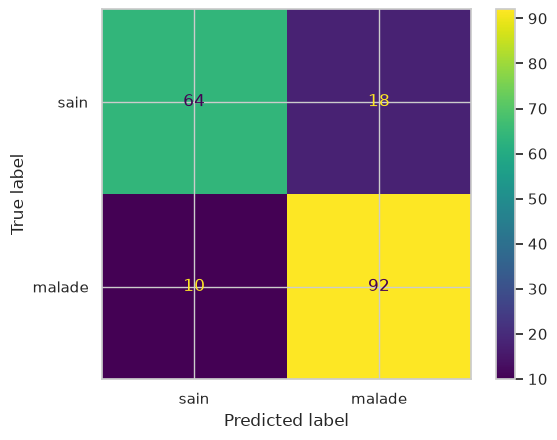

Faux négatifs (malades manqués) : 10 sur 102 malades
Faux positifs (sains alertés)   : 18 sur 82 sains


In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["sain", "malade"])
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Faux négatifs (malades manqués) : {fn} sur {fn + tp} malades")
print(f"Faux positifs (sains alertés)   : {fp} sur {fp + tn} sains")

**🔎 Interprétation (Q5)**
- **10 faux négatifs sur 102 malades** (10 % de malades manqués).
- **18 faux positifs sur 82 sains** (22 % d'alertes inutiles).
- En médecine, manquer un malade est plus grave qu'une fausse alerte : on peut **déplacer le seuil de décision** (Phase 13).

**Tâche** : courbe ROC.


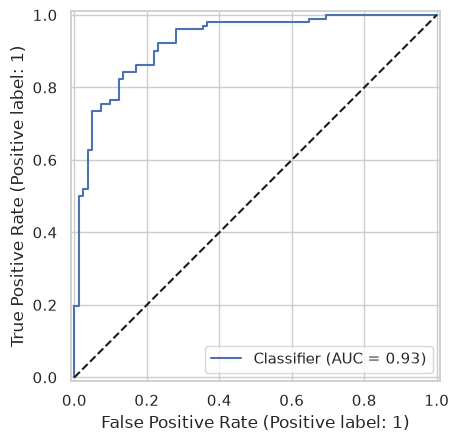

In [43]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, proba)
plt.plot([0, 1], [0, 1], "k--")       # ligne du hasard
plt.show()

**🔎 Interprétation**
- La courbe est **bien au-dessus de la diagonale** : le modèle sépare nettement mieux que le hasard.
- AUC 0,927 signifie qu'en tirant un malade et un sain au hasard, le modèle donne la **probabilité la plus haute au malade dans 93 % des cas**.
- Plus la courbe colle au coin supérieur gauche, meilleur est le compromis entre détection et fausses alertes.

### 12.2 — Les 3 modèles comparés sur le test

**Tâche** : mêmes données, trois familles de modèles (régression logistique, Random Forest, KNN) : accuracy, précision, rappel, F1, AUC, faux négatifs et faux positifs.


**L'AUC en mots simples (à retenir pour l'oral)**

Imaginez qu'on prenne **au hasard un patient malade et un patient sain**, puis qu'on demande au modèle de les classer.
- **AUC = 0,93** → dans **93 cas sur 100**, le modèle donne une probabilité plus élevée au malade qu'au sain. Il « voit » donc la différence 93 fois sur 100.
- **AUC = 0,50** → le modèle se comporte comme une pièce de monnaie (aucune info).
- **AUC = 1,00** → il classe parfaitement tous les couples.

**Ce que l'AUC ne dit pas** : combien de malades on rate **au seuil choisi**. Un modèle peut avoir 0,93 d'AUC et rater 10 malades s'il est mal calibré. C'est pour ça qu'on regarde **aussi** la matrice de confusion (rappel, FN) et le R². L'AUC répond à « classe-t-il bien ? », le rappel à « combien de malades sont manqués ? ».


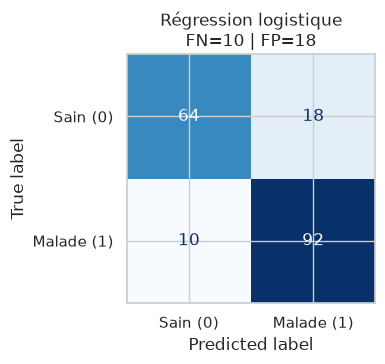

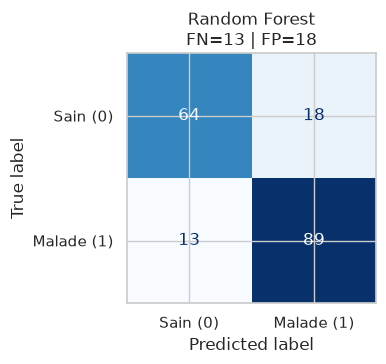

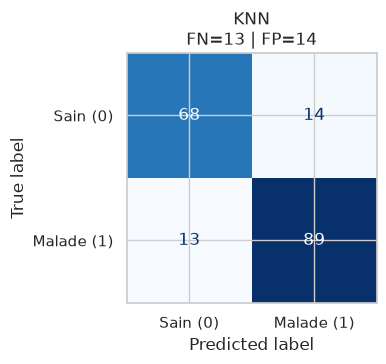

,Accuracy,Précision,Rappel,F1,AUC,FN,FP
Modèle,,,,,,,
Régression logistique,0.8478,0.8364,0.9020,0.8679,0.9267,10,18
Random Forest,0.8315,0.8318,0.8725,0.8517,0.9171,13,18
KNN,0.8533,0.8641,0.8725,0.8683,0.8981,13,14


In [44]:
# 3 modèles, mêmes données : métriques + matrices de confusion dans une seule boucle
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

modeles_cmp = {
    'Régression logistique': make(LogisticRegression(max_iter=2000)),
    'Random Forest': make(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42)),
    'KNN': make(KNeighborsClassifier(n_neighbors=7)),
}

rows = []
for nom, m in modeles_cmp.items():
    m.fit(X_train, y_train)
    pred_m, proba_m = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, pred_m)
    tn, fp, fn, tp = cm.ravel()
    rows.append({'Modèle': nom,
                 'Accuracy': accuracy_score(y_test, pred_m),
                 'Précision': precision_score(y_test, pred_m, zero_division=0),
                 'Rappel': recall_score(y_test, pred_m, zero_division=0),
                 'F1': f1_score(y_test, pred_m, zero_division=0),
                 'AUC': roc_auc_score(y_test, proba_m),
                 'FN': fn, 'FP': fp})
    fig, ax = plt.subplots(figsize=(4.5, 3.8))
    ConfusionMatrixDisplay(cm, display_labels=['Sain (0)', 'Malade (1)']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{nom}\nFN={fn} | FP={fp}')
    plt.tight_layout()
    plt.show()

pd.DataFrame(rows).set_index('Modèle').round(4)


**Interprétation (3 modèles)**

| Modèle | Accuracy | Précision | Rappel | F1 | AUC | FN | FP |
|---|---:|---:|---:|---:|---:|---:|---:|
| Régression logistique | 0,848 | 0,836 | **0,902** | 0,868 | **0,927** | **10** | 18 |
| Random Forest | 0,832 | 0,832 | 0,873 | 0,852 | 0,917 | 13 | 18 |
| KNN | **0,853** | **0,864** | 0,873 | **0,868** | 0,898 | 13 | **14** |

- **Régression logistique** : meilleure AUC et **moins de malades manqués** (10 FN) → modèle retenu.
- **KNN** : meilleure accuracy et moins de fausses alertes, mais AUC plus faible et 3 malades manqués de plus.
- **Random Forest** : entre les deux, sans avantage décisif.
- FN = malade prédit sain (risque) ; FP = sain prédit malade (fausse alerte).


## Phase 12 — Seuil de décision

**Tâche** : choisir le seuil de probabilité qui garantit un **rappel ≥ 90 %**, à partir de probabilités **out-of-fold** du train (le test reste intact).
**Pourquoi** : 0,50 est une convention ; ici, manquer un malade coûte plus cher qu'une fausse alerte, donc on accepte plus de fausses alertes pour manquer moins de malades.


In [45]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve

# Validation croisée utilisée uniquement pour obtenir des probabilités out-of-fold sur le TRAIN (pas de fuite).
# Le test reste intact.
proba_cv = cross_val_predict(make(models[meilleur]), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr, tpr, seuils = roc_curve(y_train, proba_cv)

SEUIL = float(seuils[np.argmax(tpr >= 0.90)])      # premier seuil avec rappel >= 90 %
pred_seuil = (proba >= SEUIL).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred_seuil).ravel()
print("Seuil choisi :", round(SEUIL, 2), "(au lieu de 0,50)")
print(f"Rappel : {tp / (tp + fn):.2f} | Faux négatifs : {fn} | Faux positifs : {fp}")

Seuil choisi : 0.41 (au lieu de 0,50)
Rappel : 0.92 | Faux négatifs : 8 | Faux positifs : 23


**🔎 Interprétation (Q5)**
- **Seuil de décision** : probabilité minimale pour classer un patient comme « malade (1) ». Par défaut 0,50 (50 %).
- **Seuil choisi ici : 0,41 (41 %)** — calculé automatiquement sur les prédictions **out-of-fold** du train pour obtenir un rappel ≥ 90 %.
- **Pourquoi 41 % et pas 50 % ?** Ici, on préfère une fausse alerte à un malade manqué. Abaisser le seuil augmente le rappel (plus de malades détectés) mais baisse la précision (plus de fausses alertes).
- **Ce n'est pas un chiffre magique** : il dépend du jeu de données, du modèle et du compromis choisi.
- Sur le test : **rappel 0,92**, faux négatifs **10 → 8**, mais faux positifs **18 → 23**.
- **Compromis** : 2 malades supplémentaires détectés, au prix de 5 fausses alertes de plus. Pour ce problème, ce choix est cohérent ; pour une confirmation, on privilégierait la précision.
- 8 malades restent manqués : le modèle n'est pas parfait, et c'est précisément pour cela que l'outil est une **aide à la décision**, pas une décision automatique.


## Phase 13 — Contrôle visuel : réel vs prédit

**Tâche** : placer chaque patient du test selon sa classe réelle et sa probabilité prédite, puis vérifier la calibration par tranches.
**Pourquoi** : un bon AUC ne garantit pas des probabilités honnêtes ; ce graphique montre où le modèle se trompe et si ses probabilités sont calibrées.


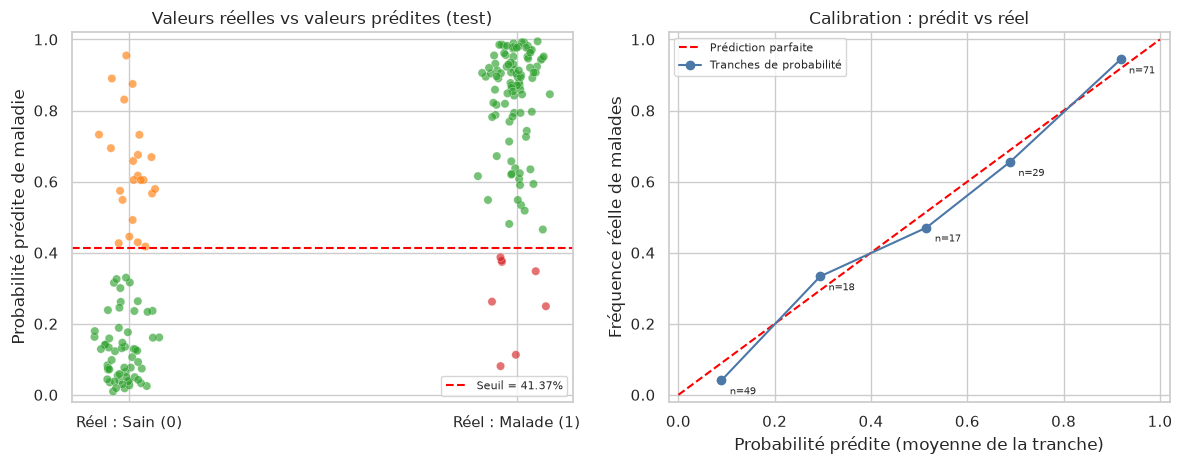

Calibration par tranche de probabilité (test) :


,pred_moyen,reel_moyen,n
tranche,,,
"(-0.001, 0.2]",0.089,0.041,49
"(0.2, 0.4]",0.294,0.333,18
"(0.4, 0.6]",0.515,0.471,17
"(0.6, 0.8]",0.688,0.655,29
"(0.8, 1.0]",0.918,0.944,71


MAE = 0.2317 | RMSE = 0.3267 | R² = 0.5680


In [46]:
yte = y_test.reset_index(drop=True)
proba_test = final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= SEUIL).astype(int)
jitter = np.random.normal(0, 0.04, len(yte))
colors = np.where((yte.values == 1) & (pred_test == 0), '#d62728',
                  np.where((yte.values == 0) & (pred_test == 1), '#ff7f0e', '#2ca02c'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ax = axes[0]
ax.scatter(yte.values + jitter, proba_test, c=colors, alpha=0.65, edgecolor='white', linewidth=0.3)
ax.axhline(SEUIL, color='red', linestyle='--', label=f'Seuil = {SEUIL:.2%}')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Réel : Sain (0)', 'Réel : Malade (1)'])
ax.set_ylabel('Probabilité prédite de maladie')
ax.set_ylim(-0.02, 1.02)
ax.set_title('Valeurs réelles vs valeurs prédites (test)')
ax.legend(loc='lower right', fontsize=8)

ax = axes[1]
cal = (pd.DataFrame({'pred': proba_test, 'reel': yte.values})
       .assign(tranche=lambda d: pd.cut(d['pred'], np.linspace(0, 1, 6), include_lowest=True))
       .groupby('tranche', observed=True)
       .agg(pred_moyen=('pred', 'mean'), reel_moyen=('reel', 'mean'), n=('reel', 'size')))
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Prédiction parfaite')
ax.plot(cal['pred_moyen'], cal['reel_moyen'], 'o-', color='#4C78A8', label='Tranches de probabilité')
for _, r in cal.iterrows():
    ax.annotate(f"n={int(r['n'])}", (r['pred_moyen'], r['reel_moyen']),
                textcoords='offset points', xytext=(6, -10), fontsize=7)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel('Probabilité prédite (moyenne de la tranche)')
ax.set_ylabel('Fréquence réelle de malades')
ax.set_title('Calibration : prédit vs réel')
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

print("Calibration par tranche de probabilité (test) :")
display(cal.round(3))

print(f"MAE = {np.mean(np.abs(yte.values - proba_test)):.4f} | "
      f"RMSE = {np.sqrt(np.mean((yte.values - proba_test) ** 2)):.4f} | "
      f"R² = {r2_score(yte.values, proba_test):.4f}")


**Interprétation des deux graphiques (réel vs prédit)**

**Panneau gauche — valeurs réelles (0/1) vs probabilité prédite.** La ligne rouge est le seuil (0,41).

| Zone | Position | Signification | Points |
|---|---|---|---|
| **Haut gauche** | réel sain (0), au-dessus du seuil | **faux positif (FP)** | orange |
| **Bas gauche** | réel sain (0), sous le seuil | **vrai négatif (TN)** | vert |
| **Haut droite** | réel malade (1), au-dessus du seuil | **vrai positif (TP)** | vert |
| **Bas droite** | réel malade (1), sous le seuil | **faux négatif (FN)** | rouge |

Les malades sont massés **en haut à droite** (probabilités 0,8–1) : c'est ce qui donne le rappel de 0,92. Les sains s'étalent en bas à gauche, avec une **queue de points orange au-dessus du seuil** : les 23 fausses alertes. Les rares points rouges (8) sont les malades manqués.

**Panneau droit — calibration : prédit vs réel par tranche de probabilité.** Chaque point = une tranche de probabilité ; si le modèle était parfaitement honnête, tous les points seraient **sur la diagonale rouge**.

| Tranche | Probabilité prédite moyenne | Fréquence réelle de malades | Patients | Lecture |
|---|---:|---:|---:|---|
| 0 – 0,2 | 0,089 | 0,041 | 49 | léger excès d'optimisme |
| 0,2 – 0,4 | 0,294 | 0,333 | 18 | **quasi parfait** |
| 0,4 – 0,6 | 0,515 | 0,471 | 17 | proche (léger excès d'optimisme) |
| 0,6 – 0,8 | 0,688 | 0,655 | 29 | proche |
| 0,8 – 1,0 | 0,918 | 0,944 | 71 | **très bonne calibration** |

**Conclusion** : le modèle est **bien calibré** — dans chaque tranche, la probabilité moyenne annoncée est proche de la fréquence réelle de malades. La zone du seuil (0,4–0,6) annonce 0,52 pour 0,47 réel : l'écart est faible. Un calibrage explicite (Platt / isotonique) reste une option de durcissement avant un usage réel, mais il n'est pas indispensable ici.

## Phase 14 — Importance des variables

**Tâche** : mesurer la contribution de chaque variable par **permutation** sur le jeu test (baisse d'AUC quand on mélange la variable).
**Pourquoi** : la corrélation mesure un lien isolé ; la permutation mesure l'usage réel de la variable **dans le modèle** (Q2).


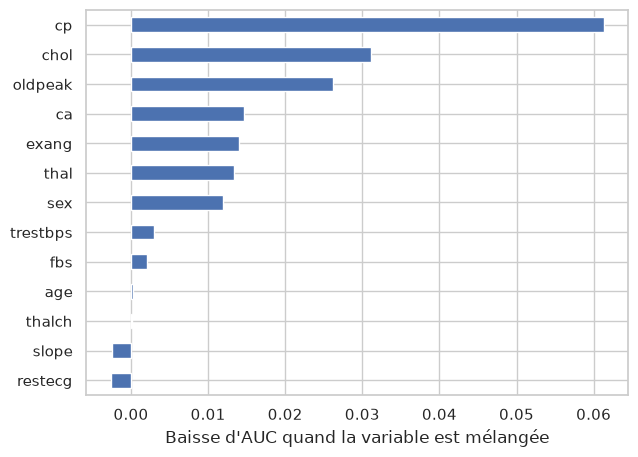

Baisse d'AUC par variable (moyenne de 20 permutations) :


,baisse d'AUC
cp,0.0613
chol,0.0311
oldpeak,0.0262
ca,0.0146
exang,0.0140
thal,0.0134
sex,0.0120
trestbps,0.0030
fbs,0.0021
age,0.0003


In [47]:
from sklearn.inspection import permutation_importance

r = permutation_importance(final, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=42)
importance = pd.Series(r.importances_mean, index=X_test.columns).sort_values()

importance.plot.barh(figsize=(7, 5))
plt.xlabel("Baisse d'AUC quand la variable est mélangée")
plt.show()

print("Baisse d'AUC par variable (moyenne de 20 permutations) :")
display(importance.sort_values(ascending=False).round(4).to_frame("baisse d'AUC"))

**Interprétation (importance des variables, Q2)**

Classement obtenu par permutation sur le jeu test (baisse d'AUC quand on mélange la variable) :

| Rang | Variable | Baisse d'AUC | Lecture |
|---|---|---:|---|
| 1 | `cp` | **0,061** | de très loin la plus utilisée par le modèle |
| 2 | `chol` | **0,031** | 2ᵉ malgré une corrélation linéaire faible (0,12) |
| 3 | `oldpeak` | 0,026 | dépression ST |
| 4 | `ca` | 0,015 | nombre de vaisseaux |
| 5 | `exang` | 0,014 | angine d'effort |
| 6 | `thal` | 0,013 | scintigraphie |
| 7 | `sex` | 0,012 | |
| 8 | `trestbps` | 0,003 | quasi inutile |
| 9 | `fbs` | 0,002 | quasi inutile |
| 10 | `age`, `thalch` | ≈ 0,000 | redondants avec le reste du modèle |
| 11 | `slope`, `restecg` | **négatif** (−0,003) | bruit : les mélanger aide un peu |

- **`cp` domine** : la façon dont la douleur thoracique se présente est le signal principal.
- **`chol` en 2ᵉ position est le résultat le plus contre-intuitif** : sa corrélation avec la maladie n'est que de 0,12, mais le modèle s'en sert beaucoup en combinaison avec les autres variables (l'information utile est dans l'écart au cholestérol attendu, pas dans le cholestérol seul).
- **`age` et `thalch` à ≈ 0** ne veulent pas dire qu'ils sont inutiles médicalement : leur information est déjà portée par `ca`, `oldpeak` et `cp`. C'est de la **redondance**, pas de l'absence de signal.
- **Baisse négative** (`slope`, `restecg`) = variable **nuisible** au sens où la mélanger améliore légèrement l'AUC. Elle reste dans le modèle car le gain est dans le bruit de mesure, mais c'est un candidat à retirer dans une version suivante.
- ⚠️ Sur 184 patients de test, ces importances sont **indicatives** : un rééchantillonnage changerait l'ordre des rangs 4 à 7.




## Phase 15 — Prédiction sur nouvelles données

**Tâche** : faire passer 3 profils types (faible risque, limite, risque élevé) dans le modèle retenu, puis comparer 3 modèles sur les mêmes profils.
**Pourquoi** : simuler l'usage réel — un patient, une probabilité, une classe.


In [48]:
SCENARIOS = {
    "Profil faible risque": {
        "age": 42, "trestbps": 120, "chol": 210, "thalch": 170, "oldpeak": 0.0, "ca": 0.0,
        "sex": "Female", "cp": "non-anginal", "fbs": "False", "restecg": "normal",
        "exang": "False", "slope": "upsloping", "thal": "normal"
    },
    "Profil vigilance (limite)": {
        "age": 55, "trestbps": 140, "chol": 245, "thalch": 145, "oldpeak": 1.0, "ca": 0.0,
        "sex": "Male", "cp": "atypical angina", "fbs": "False", "restecg": "normal",
        "exang": "False", "slope": "flat", "thal": "normal"
    },
    "Profil risque élevé": {
        "age": 63, "trestbps": 150, "chol": 280, "thalch": 120, "oldpeak": 2.3, "ca": 2.0,
        "sex": "Male", "cp": "asymptomatic", "fbs": "True", "restecg": "lv hypertrophy",
        "exang": "True", "slope": "flat", "thal": "reversable defect"
    },
}

def predire_scenario(valeurs: dict, seuil_alerte: float = None):
    seuil = float(SEUIL) if seuil_alerte is None else float(seuil_alerte)
    ligne = pd.DataFrame([valeurs])[X_train.columns]
    proba = float(final.predict_proba(ligne)[0, 1])
    classe = "Malade (1)" if proba >= seuil else "Sain (0)"
    if proba >= seuil:
        niveau = "ALERTE – vérification humaine prioritaire"
    elif proba >= seuil / 2:
        niveau = "VIGILANCE – à surveiller"
    else:
        niveau = "NORMAL"
    return {"classe_predite": classe, "probabilite_malade": round(proba, 4), "seuil": round(seuil, 4), "niveau": niveau}

rows = []
for nom, vals in SCENARIOS.items():
    r = predire_scenario(vals)
    r = {"Scénario": nom, **r}
    rows.append(r)
pd.DataFrame(rows)


,Scénario,classe_predite,probabilite_malade,seuil,niveau
0,Profil faible risque,Sain (0),0.0123,0.4137,NORMAL
1,Profil vigilance (limite),Sain (0),0.0879,0.4137,NORMAL
2,Profil risque élevé,Malade (1),0.9959,0.4137,ALERTE – vérification humaine prioritaire


**Interprétation (attendu vs prédit) :**
- Chaque ligne = un cas saisi comme dans un formulaire (données patient).
- Le profil faible risque reste sous le seuil, le profil limite aussi, le profil à risque élevé passe largement au-dessus : le modèle retrouve l'ordre attendu.
- Une **divergence** entre modèles signalerait un cas limite ; ici les trois profils sont nets.
- La validation finale doit rester humaine : c'est un prototype pédagogique.


In [49]:
# Les 3 mêmes profils passés aux 3 modèles
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

modeles_3 = {
    'Régression logistique': make(LogisticRegression(max_iter=2000)),
    'Random Forest': make(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42)),
    'KNN': make(KNeighborsClassifier(n_neighbors=7)),
}
X_new = pd.DataFrame(SCENARIOS.values())[NUM + CAT]
comparaison = pd.DataFrame({'Scénario': list(SCENARIOS)})
for nom, m in modeles_3.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_new)[:, 1]
    comparaison[f'{nom} — P(malade) %'] = (100 * p).round(1)
    comparaison[f'{nom} — classe'] = np.where(p >= SEUIL, 'Malade (1)', 'Sain (0)')
comparaison


,Scénario,Régression logistique — P(malade) %,Régression logistique — classe,Random Forest — P(malade) %,Random Forest — classe,KNN — P(malade) %,KNN — classe
0,Profil faible risque,1.2,Sain (0),1.8,Sain (0),0.0,Sain (0)
1,Profil vigilance (limite),8.8,Sain (0),23.0,Sain (0),14.3,Sain (0)
2,Profil risque élevé,99.6,Malade (1),96.0,Malade (1),100.0,Malade (1)


**Interprétation** : les 3 modèles reçoivent exactement les mêmes profils. Les probabilités se suivent (le profil à risque élevé est au-dessus du seuil pour tous), ce qui renforce la confiance ; un cas où les modèles divergeraient serait à traiter avec prudence.


In [50]:
# Tableau synthèse (valeurs réelles du test)
pred_seuil = (proba >= SEUIL).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_seuil).ravel()
synthese = pd.DataFrame({
    'Élément': ['Origine données', 'Nb observations', 'Nb variables', 'Cible', 'Split',
                'Modèle retenu', 'AUC test', 'Rappel (seuil retenu)',
                'MAE (proba)', 'MSE (proba)', 'RMSE (proba)', 'R² (proba)'],
    'Valeur': [
        'UCI/Kaggle Heart Disease (4 centres)',
        f'{len(df)} patients (après nettoyage)',
        f'{len(NUM)+len(CAT)} ({len(NUM)} num + {len(CAT)} cat)',
        'target = 1 si num > 0',
        f'Train {len(X_train)} / Test {len(X_test)} (stratifié)',
        meilleur,
        f'{roc_auc_score(y_test, proba):.4f}',
        f'{tp/(tp+fn):.4f} (FN={fn}, FP={fp})',
        f'{mean_absolute_error(y_test, proba):.4f}',
        f'{mean_squared_error(y_test, proba):.4f}',
        f'{np.sqrt(mean_squared_error(y_test, proba)):.4f}',
        f'{r2_score(y_test, proba):.4f}',
    ]
})
synthese

,Élément,Valeur
0,Origine données,UCI/Kaggle Heart Disease (4 centres)
1,Nb observations,918 patients (après nettoyage)
2,Nb variables,13 (6 num + 7 cat)
3,Cible,target = 1 si num > 0
4,Split,Train 734 / Test 184 (stratifié)
5,Modèle retenu,Régression logistique
6,AUC test,0.9267
7,Rappel (seuil retenu),"0.9216 (FN=8, FP=23)"
8,MAE (proba),0.2317
9,MSE (proba),0.1067


## Phase 16 — Export du pipeline et application

**Tâche** : réentraîner le modèle sur **toutes** les données et sauvegarder le pipeline + ses métadonnées (seuil, bornes, catégories).
**Pourquoi** : l'évaluation est terminée, tous les patients peuvent servir ; l'application charge le modèle sans le réentraîner.


In [51]:
import json, joblib

final_all = make(models[meilleur]).fit(X, y)       # réentraîné sur toutes les données
joblib.dump(final_all, "model.joblib")

meta = {
    "seuil": SEUIL,
    "num": {c: {"min": float(X[c].min()), "max": float(X[c].max()), "median": float(X[c].median())} for c in NUM},
    "cat": {c: sorted(X[c].dropna().unique().tolist()) for c in CAT},
    "citation": "Janosi, Steinbrunn, Pfisterer & Detrano (1989). Heart Disease. UCI ML Repository. https://doi.org/10.24432/C52P4X (CC BY 4.0)",
}
with open("model_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)
print("Fichiers créés : model.joblib, model_meta.json")

Fichiers créés : model.joblib, model_meta.json


**🔎 Interprétation** : deux fichiers sont créés : `model.joblib` (le pipeline complet) et `model_meta.json` (seuil, valeurs min/médiane/max, listes de catégories, citation de la source).

**Application Streamlit** : le fichier `app.py` du projet contient l'application complète (5 pages : Contexte, Processus ML, Prédiction, Notebook, Soutenance VIC).
Pour la lancer : `streamlit run app.py`.

**Pourquoi** : l'application affiche un formulaire patient, calcule la **probabilité estimée**, la compare au seuil, et rappelle l'avertissement médical et la citation du jeu de données.


## Phase 17 — Conclusion

### Les deux questions qui reviennent le plus

**1) Quel est le meilleur modèle ?**

| Modèle | AUC CV | AUC test | Rappel (seuil 0,50) | Faux négatifs |
|---|---:|---:|---:|---:|
| **Régression logistique (retenue)** | **0,883** | **0,927** | **0,90** | **10 (8 au seuil 0,41)** |
| Random Forest | 0,876 | 0,917 | 0,87 | 13 |
| KNN | 0,864 | 0,898 | 0,87 | 13 |
| Arbre de décision | 0,804 | — | — | — |

➡️ **La régression logistique est le meilleur modèle** : meilleure AUC en validation croisée **et** sur le test, le meilleur rappel au seuil retenu (8 malades manqués sur 102, contre 13 pour Random Forest et KNN), et le plus **explicable** (un coefficient par variable, donc un discours clinique possible). La vérification à 8 familles (Phase 11.2) ne change pas la conclusion.

**2) Valeurs manquantes : patient similaire (KNN) ou médiane/mode ?**

Comparaison **avec le modèle livré** (régression logistique, seuil 0,50) et sur les critères du projet (**rappel**, puis **R²**) — pas sur l'AUC seule :

| Stratégie | TP/TN/FP/FN | Rappel | R² (proba) | CV R² | AUC |
|---|---|---:|---:|---:|---:|
| 1. (retiré) | 91/63/19/11 | 0,8922 | 0,5409 | 0,4334 | 0,9200 |
| 2. **Médiane / mode (livrée)** | 92/64/18/10 | **0,9020** | 0,5680 | 0,4554 | **0,9267** |
| 3. Patient similaire (KNN) | 92/65/17/10 | **0,9020** | **0,5743** | **0,4696** | 0,9249 |

➡️ **Verdict corrigé : les deux se valent ; le KNN n'est pas moins bon.** Rappel **identique** (10 malades manqués sur 102), R² **légèrement meilleur pour le KNN** (0,5743 contre 0,5680 ; 0,4696 contre 0,4554 en CV R²), AUC et CV-rappel très légèrement meilleurs pour la médiane. Les IC bootstrap appariés contiennent 0 → **aucune supériorité démontrée**.

➡️ **Pourquoi la médiane/mode est quand même celle qui est livrée** : une seule valeur apprise par variable (rien à stocker), **valeurs imputées auditables** (`ca = 0` est explicite) et c'est **elle qui est déjà exportée** dans `model.joblib` et l'application. C'est un choix de **simplicité et de transparence**, pas une victoire chiffrée.

➡️ **Le vrai défaut du KNN ici** : pour `thal`, il **moyenne des codes** (`normal` 0 / `fixed` 1 / `reversable` 2), ce qui n'a aucun sens sur une nominale — il produit **50,9 % de `fixed defect`** alors que cette modalité ne pèse que **10,9 %** des cas réels. Son avantage conceptuel reste réel pour `ca` (48 % de 0 / 44 % de 1 au lieu de 100 % de 0), mais il est gâché par cette moyenne de codes.


**Réponses aux questions de recherche**
- **Q1 — Facteurs associés à la maladie** (Phase 7) : côté **numériques** (Pearson), `ca` **+0,456** (309 patients seulement), `thalch` **−0,393**, `oldpeak` **+0,386**, `age` **+0,282**, `chol` +0,119, `trestbps` +0,115. Côté **catégories**, on lit les **taux de malades** : `cp = asymptomatic` **79 %** contre 13,9 % pour `atypical angina`, `exang = True` **83,6 %** contre 36,4 %, `thal` anormal **76–80 %** contre 29,6 % si `normal`, `slope` flat/downsloping **~77 %** contre 38,4 % en upsloping, homme **63,2 %** contre femme 25,9 %. Aucun coefficient n'est calculé sur une variable catégorielle : ce sont des proportions.
- **Q2 — Variables les plus contributives** (permutation, Phase 15) : `cp` très largement en tête (**0,061** d'AUC), puis `chol` (**0,031**), `oldpeak` (0,026), `ca` (0,015), `exang` (0,014), `thal` (0,013), `sex` (0,012). `age` et `thalch` ressortent à ≈ 0 : leur information est déjà portée par les autres variables. `chol` est le cas le plus instructif : corrélation faible avec la cible (0,12) mais **2ᵉ contribution** dans le modèle — la corrélation seule ne suffit pas à juger de l'utilité d'une variable.
- **Q3 — Capacité prédictive** : **AUC 0,927** sur le test (CV 0,883), accuracy **0,848**, précision 0,836, rappel 0,902. Soit 156 bons pronostics sur 184 patients.
- **Q4 — Meilleur modèle** : la **régression logistique** (AUC CV 0,883), devant Random Forest (0,876), KNN (0,864) et l'arbre de décision (0,804) ; la vérification à 8 modèles ne change pas la conclusion (SVM 0,879, juste derrière, mais moins explicable). Pour les valeurs manquantes, l'étude comparative (Phase 10, rejouée avec le modèle livré) montre que **médiane/mode et patient similaire (KNN) se valent** : rappel identique 0,902 (10 FN), R² 0,5680 contre 0,5743, CV R² 0,4554 contre 0,4696, IC bootstrap contenant 0 → aucune supériorité démontrée. La **médiane/mode est livrée** pour sa simplicité et la transparence de ses valeurs imputées ; la suppression de `ca`/`thal` est derrière (rappel 0,8922, 11 FN).
- **Q5 — Fiabilité de la détection** : rappel **0,90** au seuil 0,5 (10 faux négatifs sur 102 malades, 18 faux positifs sur 82 sains). Avec le **seuil 0,41** : rappel **0,92**, **8 faux négatifs**, 23 faux positifs. On échange 2 malades détectés en plus contre 5 fausses alertes en plus — arbitrage assumé.

**Limites à citer dans le rapport**
- **Manquants massifs** : `ca` (66 %) et `thal` (53 %) sont imputés, donc **inventés**. La Phase 10 compare suppression, médiane/mode et KNN : les écarts sont faibles et les IC se recoupent, aucune supériorité n'est démontrée statistiquement.
- **Doublons** : 2 paires de lignes exactement identiques retirées (920 → 918). Elles ne changeaient pas les conclusions, mais les compter deux fois donnait un poids double à ces profils.
- **Centres hétérogènes** : le taux de maladie varie fortement selon le centre (36 % en Hongrie, 93 % en Suisse) et les manquants dépendent du centre : risque de raccourci géographique.
- **Échantillon** très masculin (79 %), données **anciennes** (1988), **aucune validation externe**, notamment pour une population tunisienne.
- **Test de 184 patients** : métriques, IC et importances sont **indicatifs** ; un autre découpage déplacerait les décimales.
- **Le modèle ne prédit pas une crise cardiaque** : c'est un prototype pédagogique, qui ne remplace pas un avis médical.


## Conclusion finale — le verdict

**Modèle retenu : régression logistique** (pipeline médiane/mode + scaling + one-hot, seuil 0,41).
**Valeurs manquantes : médiane / mode** (pas le patient le plus proche, pas la suppression).
**Usage : aide à la décision** — prototype pédagogique.

### 1. Matrice de confusion réelle (test = 184 patients : 82 sains, 102 malades)

| Seuil | TN (sain → sain) | FP (sain → malade) | FN (malade → sain) | TP (malade → malade) | Accuracy | Rappel | Spécificité | Précision |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 0,50 | 64 | 18 | 10 | 92 | 0,848 | 0,902 | 0,780 | 0,836 |
| **0,41 (retenu)** | 59 | 23 | **8** | **94** | 0,832 | **0,922** | 0,720 | 0,803 |

**Lecture** : sur 102 malades, le modèle en détecte **94** et en manque **8** (FN) ; sur 82 sains, **59** sont correctement rassurés (TN) et **23** reçoivent une fausse alerte (FP). Abaisser le seuil de 0,50 à 0,41 **échange 2 malades manqués contre 5 fausses alertes** — arbitrage assumé, puisqu'une alerte mène à un examen et qu'un malade manqué passe inaperçu.

- **TP/TN** = décisions correctes (**153/184** au seuil 0,41).
- **FP** = coût de temps et d'anxiété, jamais un risque vital direct.
- **FN** = l'erreur critique : 8 cas, tous visibles sur le graphique réel vs prédit (Phase 13).
- **VPN (TN/(TN+FN)) = 0,881 au seuil retenu** (0,865 au seuil 0,50) : quand le modèle dit « sain », il a raison ~88 % du temps.

### 2. Métriques d'erreur et R² — ce qu'elles disent vraiment

| Métrique | Probabilité | Classe 0/1 | Interprétation |
|---|---:|---:|---|
| MAE | 0,2317 | 0,1522 | écart moyen de 0,23 entre la probabilité prédite et la réalité |
| MSE | 0,1067 | 0,1522 | pénalise les erreurs confiantes |
| RMSE | 0,3267 | 0,3901 | même unité qu'une probabilité, donc lisible |
| **R²** | **0,5680** | 0,3840 | **57 % de la variance des étiquettes expliquée** |

**Comment interpréter le R² = 0,568** : la cible est binaire, donc la variance à expliquer est celle d'une suite de 0 et de 1 — un R² ne peut **pas** approcher 1 dans ce cas, et 0,568 est une valeur **élevée** pour une classification (le plafond pratique tourne autour de 0,6). Concrètement : le modèle fait **nettement mieux que prédire la moyenne** (R² = 0 = pronostic constant), mais il reste 43 % de variance inexpliquée, ce qui est normal : il manque les facteurs non mesurés (tabac, antécédents familiaux, biologie fine). Sur la classe prédite, R² = 0,384 et MAE = MSE = 0,1522 (= taux d'erreur) : ces deux chiffres mesurent la même chose, l'erreur de décision.

**Ce que le R² ne dit pas** : combien de malades ont été manqués. Les deux erreurs y pèsent pareil. C'est pourquoi la décision se lit avec la **matrice de confusion + le rappel**, et le R² sert de **contrôle méthodologique** (exigence VIC, comparaison de modèles) : **rappel → AUC → précision/F1 → R²/MAE/MSE/RMSE**.

### 3. Pourquoi ces choix, en une phrase chacun

| Question | Réponse | Preuve |
|---|---|---|
| Meilleur modèle ? | **Régression logistique** | AUC CV **0,883** (devant RF 0,876, KNN 0,864, arbre 0,804), AUC test **0,927**, et 8 malades manqués au lieu de 13 |
| Meilleure imputation ? | **Équivalentes : KNN et médiane/mode** | rappel identique (0,9020), R² **0,5743 (KNN) vs 0,5680 (médiane)** ; IC contenant 0 → pas de gagnant démontré |
| Pourquoi pas le patient le plus proche ? | Écarté pour **simplicité/transparence**, pas pour performance | il est à égalité sur le rappel et devant sur le R², mais il **moyenne des codes** pour `thal` (50,9 % de `fixed defect` contre 10,9 % en réel) |
| Pourquoi pas supprimer `ca`/`thal` ? | **Perte d'information** | rappel 0,8922 (11 FN), R² 0,5409 et deux examens jetés |
| Pourquoi le seuil 0,41 ? | **Rappel ≥ 90 % visé** | 8 FN au lieu de 10, au prix de 5 FP de plus |

### 4. Limites et suite

- 918 patients, **4 centres** aux pratiques différentes ; `ca` (309 connus) et `thal` (434) très incomplets.
- Données **rétrospectives** : le modèle décrit cette cohorte, il ne prouve pas une généralisation.
- Probabilités **globalement bien calibrées** sur ce test (Phase 13), mais rien ne garantit cette calibration sur une autre population.
- **Suite** : validation externe sur un autre hôpital, calibration (Brier / courbe de fiabilité), suivi de dérive.
- **Rappel de sécurité** : prototype pédagogique ; toute décision médicale revient à un professionnel.
